# Tugas Akhir Fase 1 — Customer Behavior & Retail Transaction Analysis

**Track:** Data Science Competition Track | **Dataset:** `customer_behavior_phase1.csv` (10.000 transaksi tahun 2026, 19 kolom variabel)

### Daftar Isi
1. **Bagian A (Bobot 25%) — Dasar Data dan Pemahaman Granularitas:** Klasifikasi 19 variabel (A.1), audit kualitas data & deteksi anomali operasional (A.2), dan analisis tingkat transaksi vs. pelanggan unik (A.3).
2. **Bagian B (Bobot 35%) — Statistik Deskriptif dan Evaluasi Outlier:** Ukuran pemusatan & penyebaran (B.1), interpretasi distribusi `Purchase_Amount` & `Age` (B.2), serta deteksi outlier IQR, segmentasi kewajaran, uji sensitivitas, dan rekomendasi penanganan (B.3).
3. **Bagian C (Bobot 40%) — Visualisasi Data dan Investigasi Pola Bisnis:** Dinamika waktu belanja (C.1), kontribusi geografis (C.2), pengaruh membership & kategori produk termasuk uji ketahanan terhadap baris mencurigakan (C.3), korelasi kepuasan pelanggan (C.4), verifikasi angka (C.5), dan 3 rekomendasi bisnis strategis (C.6).

### Catatan Alur Data & Konvensi Analisis
* **Alur Data Terpadu (A → B → C):**
  * **Bagian A** mengaudit dataset mentah `customer_behavior_phase1.csv` (`df_raw`, **10.000 baris**) untuk membuktikan kelengkapan, duplikasi, konsistensi rumus, serta mengisolasi **443 baris anomali operasional gerai fisik** menjadi dataset bersih `TugasBagianA_Bersih.xlsx` sheet `Data_Bersih` (**9.557 baris**).
  * **Bagian B dan Bagian C** sama-sama menggunakan `Data_Bersih` (`df`, **9.557 baris**) sebagai **basis data utama** agar seluruh metrik statistik, evaluasi outlier, visualisasi, dan rekomendasi bisnis konsisten pada satu populasi yang sama. Dataset mentah (`df_raw`) disertakan di Bagian B.1 dan B.3 sebagai **pembanding** untuk memastikan pembersihan Bagian A tidak menggeser kesimpulan statistik.
* **Konvensi Satuan & Metrik:**
  * `Discount_Percentage` diseragamkan ke skala persen **`0–50%`** (dari pecahan `0–0,5` pada file Excel bersih).
  * Seluruh nilai transaksi dinyatakan dalam **Rupiah (Rp)**, dan **median** digunakan sebagai ukuran utama "belanja tipikal" karena distribusi `Purchase_Amount` sangat miring ke kanan.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)
pd.set_option('display.float_format', '{:,.2f}'.format)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

os.makedirs('charts', exist_ok=True)

def fmt_id(x, nd=0):
    """Format angka gaya Indonesia: titik ribuan, koma desimal."""
    return f"{x:,.{nd}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def rp_singkat(x, _=None):
    """Format ringkas sumbu Rupiah (rb, jt, M)."""
    if x >= 1e9:
        return f"{x / 1e9:g} M"
    if x >= 1e6:
        return f"{x / 1e6:g} jt"
    if x >= 1e3:
        return f"{x / 1e3:g} rb"
    return f"{x:g}"

def rp_pendek(x):
    """Format teks pendek nilai Rupiah dalam satuan juta atau ribu."""
    return f"Rp {fmt_id(x / 1e6, 2)} jt" if x >= 1e6 else f"Rp {fmt_id(x / 1e3)} rb"

def batas_iqr(s):
    """Hitung Q1, Q3, IQR, batas bawah, dan batas atas metode 1.5*IQR."""
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1, q3, iqr, q1 - 1.5 * iqr, q3 + 1.5 * iqr

In [2]:
# Data mentah: dipakai untuk audit Bagian A dan pembanding Bagian B
df_raw = pd.read_csv('customer_behavior_phase1.csv')

# Data bersih hasil Bagian A.2: basis utama Bagian B dan Bagian C
df = pd.read_excel('TugasBagianA_Bersih.xlsx', sheet_name='Data_Bersih')
df['Discount_Percentage'] = df['Discount_Percentage'] * 100
df['Purchase_Date'] = pd.to_datetime(df['Purchase_Date'])
df['Month'] = df['Purchase_Date'].dt.month
df['Day_of_Month'] = df['Purchase_Date'].dt.day

print('Data mentah (df_raw) :', df_raw.shape)
print('Data bersih (df)     :', df.shape)
print('Maks diskon df (%)   :', df['Discount_Percentage'].max())
display(df_raw.head())

Data mentah (df_raw) : (10000, 19)
Data bersih (df)     : (9557, 21)
Maks diskon df (%)   : 50.0


,Transaction_ID,Customer_ID,Age,Gender,City,Region,Membership_Level,Product_Category,Product_Name,Quantity,Unit_Price,Discount_Percentage,Purchase_Amount,Payment_Method,Store_Type,Purchase_Date,Purchase_Hour,Purchase_Day,Customer_Satisfaction
0,TRX-000001,CUST-02118,35,Female,Jakarta,Jabodetabek,Gold,Groceries,Assorted Snack Box,5,"104,000.00",0.00,"520,000.00",QRIS,Online App,2026-01-01,3,Thursday,3
1,TRX-000002,CUST-03099,26,Male,Yogyakarta,Central Java,Basic,Home & Living,Air Purifier Mini,2,"304,000.00",20.00,"486,400.00",Credit Card,Online App,2026-01-01,5,Thursday,1
2,TRX-000003,CUST-01259,37,Female,Sidoarjo,East Java,Basic,Fashion,Casual Chino Pants,2,"427,000.00",10.00,"768,600.00",E-Wallet,Online App,2026-01-01,8,Thursday,1
3,TRX-000004,CUST-02153,33,Male,Medan,Sumatera,Premium,Home & Living,Ceramic Coffee Dripper,3,"426,000.00",5.00,"1,214,100.00",E-Wallet,Official Web,2026-01-01,8,Thursday,4
4,TRX-000005,CUST-00942,31,Male,Tangerang,Jabodetabek,Basic,Beauty & Health,Hydrating Facial Cleanser,3,"92,000.00",5.00,"262,200.00",Debit Card,Flagship Store,2026-01-01,8,Thursday,5


# BAGIAN A: Dasar Data dan Pemahaman Granularitas (Bobot: 25%)

**Basis data:** `customer_behavior_phase1.csv` (`df_raw`, **10.000 baris transaksi**, 19 kolom variabel).  
Bagian ini membuktikan secara kuantitatif **A.1 (Klasifikasi Variabel)**, **A.2 (Audit Kualitas Data)**, dan **A.3 (Analisis Tingkat Pelanggan vs. Tingkat Transaksi)**, melengkapi workbook Excel `TugasBagianA_Kelompok.xlsx` dan menghasilkan dataset bersih `TugasBagianA_Bersih.xlsx`.

In [3]:
# Dimensi dan tipe data tiap kolom pada CSV asli
print("Ukuran dataset:", df_raw.shape)
df_raw.info()

Ukuran dataset: (10000, 19)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Transaction_ID         10000 non-null  str    
 1   Customer_ID            10000 non-null  str    
 2   Age                    10000 non-null  int64  
 3   Gender                 10000 non-null  str    
 4   City                   10000 non-null  str    
 5   Region                 10000 non-null  str    
 6   Membership_Level       10000 non-null  str    
 7   Product_Category       10000 non-null  str    
 8   Product_Name           10000 non-null  str    
 9   Quantity               10000 non-null  int64  
 10  Unit_Price             10000 non-null  float64
 11  Discount_Percentage    10000 non-null  float64
 12  Purchase_Amount        10000 non-null  float64
 13  Payment_Method         10000 non-null  str    
 14  Store_Type             10000 non-null 

## A.1 Klasifikasi Variabel

Pengelompokan 19 kolom sesuai **Deskripsi Kolom Dataset** (dipisahkan ke 6 sheet pada `TugasBagianA_Kelompok.xlsx`):
1. **Identifier (2):** `Transaction_ID`, `Customer_ID`
2. **Nominal (7):** `Gender`, `City`, `Region`, `Product_Category`, `Product_Name`, `Payment_Method`, `Store_Type`
3. **Ordinal (3):** `Membership_Level`, `Purchase_Day`, `Customer_Satisfaction`
4. **Diskrit (3):** `Age`, `Quantity`, `Purchase_Hour`
5. **Kontinu (3):** `Unit_Price`, `Discount_Percentage`, `Purchase_Amount`
6. **Temporal (1):** `Purchase_Date`

**Alasan klasifikasi khusus:**
1. **`Customer_Satisfaction` (Ordinal):** Walaupun tersimpan sebagai angka `1` s.d. `5`, variabel ini merupakan skala Likert yang menyatakan tingkatan persepsi kepuasan (`1 < 2 < 3 < 4 < 5`), dengan jarak psikologis antar skor tidak dijamin seragam dan tanpa titik nol absolut.
2. **`Purchase_Hour` (Numerik Diskrit):** Nilainya berupa bilangan bulat terbatas yang dapat dicacah dalam format 24 jam (`0` s.d. `23`, tanpa pecahan) sesuai deskripsi dataset, dengan karakteristik waktu siklis (jam `23` berdekatan dengan jam `0`).

In [4]:
# Jumlah nilai unik tiap kolom
df_raw.nunique()

Transaction_ID           10000
Customer_ID               2876
Age                         47
Gender                       2
City                        17
Region                       5
Membership_Level             4
Product_Category             5
Product_Name                26
Quantity                    47
Unit_Price                1784
Discount_Percentage          9
Purchase_Amount           5307
Payment_Method               6
Store_Type                   4
Purchase_Date              365
Purchase_Hour               24
Purchase_Day                 7
Customer_Satisfaction        5
dtype: int64

## A.2 Audit Kualitas Data

### 1. Pembuktian Missing Value

In [5]:
# Jumlah missing value per kolom
df_raw.isnull().sum()

Transaction_ID           0
Customer_ID              0
Age                      0
Gender                   0
City                     0
Region                   0
Membership_Level         0
Product_Category         0
Product_Name             0
Quantity                 0
Unit_Price               0
Discount_Percentage      0
Purchase_Amount          0
Payment_Method           0
Store_Type               0
Purchase_Date            0
Purchase_Hour            0
Purchase_Day             0
Customer_Satisfaction    0
dtype: int64

In [6]:
# Total missing value dan string kosong pada kolom teks
print("Total missing value di seluruh dataset:", df_raw.isnull().sum().sum())

kolom_teks = df_raw.select_dtypes(include=['object', 'string']).columns
total_kosong = 0
for col in kolom_teks:
    kosong = (df_raw[col].str.strip() == '').sum()
    total_kosong += kosong
print("Total string kosong / spasi kosong    :", total_kosong)

Total missing value di seluruh dataset: 0
Total string kosong / spasi kosong    : 0


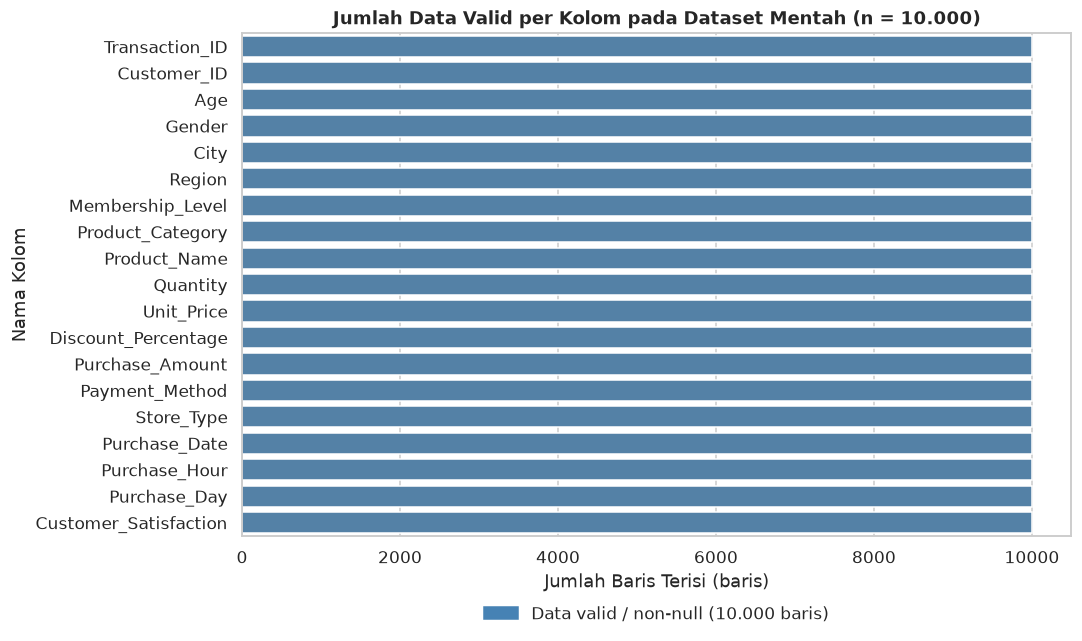

In [7]:
# Diagram jumlah data valid per kolom
plt.figure(figsize=(10, 6))
sns.barplot(x=df_raw.notnull().sum().values, y=df_raw.columns, color='steelblue')
plt.title('Jumlah Data Valid per Kolom pada Dataset Mentah (n = 10.000)', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Baris Terisi (baris)')
plt.ylabel('Nama Kolom')
plt.legend(
    handles=[Patch(color='steelblue', label='Data valid / non-null (10.000 baris)')],
    loc='upper center', bbox_to_anchor=(0.5, -0.11), frameon=False
)
plt.tight_layout()
plt.savefig('charts/A_kelengkapan_kolom.png', dpi=300, bbox_inches='tight')
plt.show()

**Insight Grafik A.1 (Kelengkapan Data).** Seluruh 19 kolom pada `customer_behavior_phase1.csv` memiliki tepat 10.000 baris non-null (100% terisi) dan 0 string kosong pada kolom teks. Secara bisnis, kondisi ini memastikan tidak ada transaksi atau profil pelanggan yang hilang akibat kegagalan pencatatan dasar, sehingga audit berikutnya dapat berfokus pada konsistensi relasional dan kewajaran operasional tanpa perlu proses imputasi.

### 2. Pembuktian Duplikasi Data

In [8]:
# Jumlah baris duplikat identik pada seluruh 19 kolom
df_raw.duplicated().sum()

np.int64(0)

In [9]:
# Duplikasi Transaction_ID, isi transaksi tanpa ID, dan jumlah Customer_ID unik
print("Duplikat Transaction_ID                  :", df_raw['Transaction_ID'].duplicated().sum())

kolom_non_id = [col for col in df_raw.columns if col != 'Transaction_ID']
print("Duplikat transaksi (tanpa Transaction_ID):", df_raw.duplicated(subset=kolom_non_id).sum())

print("Total baris transaksi                    :", len(df_raw))
print("Jumlah Customer_ID unik                  :", df_raw['Customer_ID'].nunique())

Duplikat Transaction_ID                  : 0
Duplikat transaksi (tanpa Transaction_ID): 0
Total baris transaksi                    : 10000
Jumlah Customer_ID unik                  : 2876


### 3. Pembuktian Konsistensi Perhitungan Matematis (`Purchase_Amount`)

In [10]:
# Validasi rumus Purchase_Amount terhadap Quantity, Unit_Price, dan Discount_Percentage
gross = df_raw['Quantity'] * df_raw['Unit_Price']
expected_amount = gross - (gross * df_raw['Discount_Percentage'] / 100)
selisih = (df_raw['Purchase_Amount'] - expected_amount).abs()

print("Jumlah baris tidak konsisten (selisih > 0.01):", (selisih > 0.01).sum())
print("Selisih maksimum (Rp)                        :", selisih.max())

cek_math = df_raw[['Transaction_ID', 'Quantity', 'Unit_Price', 'Discount_Percentage', 'Purchase_Amount']].head().copy()
cek_math['Expected_Amount'] = expected_amount.head()
cek_math['Selisih'] = selisih.head()
cek_math

Jumlah baris tidak konsisten (selisih > 0.01): 0
Selisih maksimum (Rp)                        : 0.0


,Transaction_ID,Quantity,Unit_Price,Discount_Percentage,Purchase_Amount,Expected_Amount,Selisih
0,TRX-000001,5,"104,000.00",0.00,"520,000.00","520,000.00",0.00
1,TRX-000002,2,"304,000.00",20.00,"486,400.00","486,400.00",0.00
2,TRX-000003,2,"427,000.00",10.00,"768,600.00","768,600.00",0.00
3,TRX-000004,3,"426,000.00",5.00,"1,214,100.00","1,214,100.00",0.00
4,TRX-000005,3,"92,000.00",5.00,"262,200.00","262,200.00",0.00


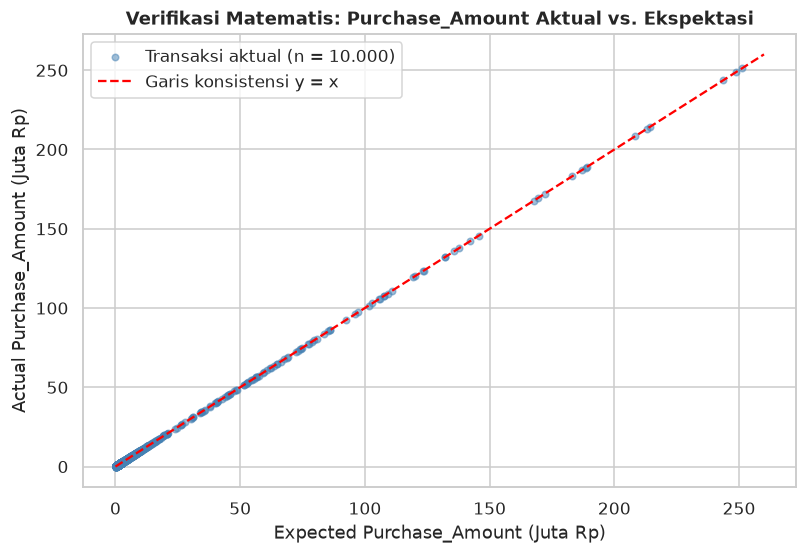

In [11]:
# Scatter plot Purchase_Amount aktual vs ekspektasi
plt.figure(figsize=(7.5, 5.2))
plt.scatter(expected_amount / 1e6, df_raw['Purchase_Amount'] / 1e6, alpha=0.5, s=18,
            color='steelblue', label='Transaksi aktual (n = 10.000)')
plt.plot([0, 260], [0, 260], color='red', linestyle='--', linewidth=1.5, label='Garis konsistensi y = x')
plt.title('Verifikasi Matematis: Purchase_Amount Aktual vs. Ekspektasi', fontsize=12, fontweight='bold')
plt.xlabel('Expected Purchase_Amount (Juta Rp)')
plt.ylabel('Actual Purchase_Amount (Juta Rp)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('charts/A_verifikasi_matematis.png', dpi=300, bbox_inches='tight')
plt.show()

**Insight Grafik A.2 (Verifikasi Matematis).** Seluruh 10.000 titik transaksi jatuh tepat pada garis diagonal $y = x$ dengan selisih maksimum Rp 0,00 terhadap rumus `Quantity × Unit_Price × (1 - Discount_Percentage/100)`. Hal ini membuktikan tidak ada kesalahan aritmetika ataupun manipulasi angka pada kolom `Purchase_Amount`, sehingga apabila muncul nilai transaksi ekstrem pada Bagian B, sumbernya dipastikan berasal dari komponen `Quantity` atau `Unit_Price`.

### 4. Audit Tipe Data, Konsistensi Relasional, dan Anomali Operasional

In [12]:
# Konsistensi tanggal Purchase_Date terhadap Purchase_Day
tgl = pd.to_datetime(df_raw['Purchase_Date'])
print("Format tanggal tidak valid    :", tgl.isnull().sum())
print("Mismatch Purchase_Day         :", (tgl.dt.day_name() != df_raw['Purchase_Day']).sum())

# Konsistensi relasi City ke Region, Product_Name ke Product_Category, dan profil Customer_ID
print("City dengan >1 Region         :", (df_raw.groupby('City')['Region'].nunique() > 1).sum())
print("Produk dengan >1 Kategori     :", (df_raw.groupby('Product_Name')['Product_Category'].nunique() > 1).sum())
profil_cols = ['Age', 'Gender', 'City', 'Region', 'Membership_Level']
print("Konflik profil per Customer_ID:", int((df_raw.groupby('Customer_ID')[profil_cols].nunique() > 1).sum().sum()))

# Pengecekan tipe penyimpanan kolom pada CSV asli
print("\nKetidaksesuaian tipe penyimpanan CSV:")
print("1. Purchase_Date dtype          :", df_raw['Purchase_Date'].dtype, "(tersimpan sebagai teks, belum datetime)")
print("2. Unit_Price nilai pecahan     :", (df_raw['Unit_Price'] % 1 != 0).sum(), "| dtype:", df_raw['Unit_Price'].dtype)
print("3. Discount_Percentage pecahan  :", (df_raw['Discount_Percentage'] % 1 != 0).sum(), "| dtype:", df_raw['Discount_Percentage'].dtype)
print("4. Purchase_Amount pecahan      :", (df_raw['Purchase_Amount'] % 1 != 0).sum(), "| dtype:", df_raw['Purchase_Amount'].dtype)

Format tanggal tidak valid    : 0
Mismatch Purchase_Day         : 0
City dengan >1 Region         : 0
Produk dengan >1 Kategori     : 0
Konflik profil per Customer_ID: 0

Ketidaksesuaian tipe penyimpanan CSV:
1. Purchase_Date dtype          : str (tersimpan sebagai teks, belum datetime)
2. Unit_Price nilai pecahan     : 0 | dtype: float64
3. Discount_Percentage pecahan  : 0 | dtype: float64
4. Purchase_Amount pecahan      : 0 | dtype: float64


In [13]:
# Identifikasi anomali operasional gerai fisik (Cash pada kanal daring dipertahankan karena valid sebagai COD)
m_online_cash = df_raw['Store_Type'].isin(['Online App', 'Official Web']) & (df_raw['Payment_Method'] == 'Cash')
m_phys_night = df_raw['Store_Type'].isin(['Flagship Store', 'Mall Outlet']) & ((df_raw['Purchase_Hour'] < 8) | (df_raw['Purchase_Hour'] >= 23))

phys_df = df_raw[df_raw['Store_Type'].isin(['Flagship Store', 'Mall Outlet'])]
konflik_keys = phys_df.groupby(['Customer_ID', 'Purchase_Date', 'Purchase_Hour'])['Store_Type'].nunique()
bad_keys = konflik_keys[konflik_keys > 1].index
m_phys_conflict = df_raw.set_index(['Customer_ID', 'Purchase_Date', 'Purchase_Hour']).index.isin(bad_keys) & df_raw['Store_Type'].isin(['Flagship Store', 'Mall Outlet'])

total_anomali = (m_phys_night | m_phys_conflict).sum()

print("Catatan Cash pada kanal daring (valid COD, dipertahankan)       :", int(m_online_cash.sum()), "baris")
print("1. Gerai fisik di luar jam operasional (00:00 s.d. 07:00 & 23:00):", int(m_phys_night.sum()), "baris")
print("2. Customer_ID sama di 2 gerai fisik pada tanggal & jam sama     :", int(m_phys_conflict.sum()), "baris")
print("Total baris anomali (dipisahkan ke Data_Dikeluarkan)             :", int(total_anomali), "baris")
print("Total baris bersih (Data_Bersih)                                 :", len(df_raw) - int(total_anomali), "baris")

# Distribusi usia batas atas (Age 60 s.d. 65)
print("\nDistribusi usia batas atas (Age 60 s.d. 65):")
df_raw['Age'].value_counts().sort_index().loc[60:65]

Catatan Cash pada kanal daring (valid COD, dipertahankan)       : 349 baris
1. Gerai fisik di luar jam operasional (00:00 s.d. 07:00 & 23:00): 437 baris
2. Customer_ID sama di 2 gerai fisik pada tanggal & jam sama     : 6 baris
Total baris anomali (dipisahkan ke Data_Dikeluarkan)             : 443 baris
Total baris bersih (Data_Bersih)                                 : 9557 baris

Distribusi usia batas atas (Age 60 s.d. 65):


Age
60     35
61     43
62     21
63     17
64     10
65    100
Name: count, dtype: int64

## A.3 Analisis Tingkat Pelanggan vs. Tingkat Transaksi

Perbandingan rata rata `Age` dan persentase `Gender` pada **10.000 baris transaksi** vs. **2.876 pelanggan unik (`Customer_ID`)** (tabel deskriptif dan histogram Excel tersedia di sheet `A3_Analisis_Deskriptif` pada `TugasBagianA_Kelompok.xlsx`).

In [14]:
# Deduplikasi pelanggan unik berdasarkan Customer_ID
df_pelanggan = df_raw.drop_duplicates(subset=['Customer_ID']).copy()

print("Total Transaksi      :", len(df_raw))
print("Total Pelanggan Unik :", len(df_pelanggan))
print("Rata rata Trx/Cust   :", round(len(df_raw) / len(df_pelanggan), 2))

# Perbandingan statistik Age
print("\n=== Perbandingan Usia (Age) ===")
print(f"Tingkat Transaksi      : Mean = {df_raw['Age'].mean():.2f}, Median = {df_raw['Age'].median():.2f}, Mode = {df_raw['Age'].mode()[0]}, Std = {df_raw['Age'].std():.2f}")
print(f"Tingkat Pelanggan Unik : Mean = {df_pelanggan['Age'].mean():.2f}, Median = {df_pelanggan['Age'].median():.2f}, Mode = {df_pelanggan['Age'].mode()[0]}, Std = {df_pelanggan['Age'].std():.2f}")

# Perbandingan distribusi Gender (%)
gender_trx = df_raw['Gender'].value_counts(normalize=True) * 100
gender_cust = df_pelanggan['Gender'].value_counts(normalize=True) * 100

tabel_gender = pd.DataFrame({
    'Transaksi_Count': df_raw['Gender'].value_counts(),
    'Transaksi_%': gender_trx.round(2),
    'Pelanggan_Unik_Count': df_pelanggan['Gender'].value_counts(),
    'Pelanggan_Unik_%': gender_cust.round(2),
})
tabel_gender

Total Transaksi      : 10000
Total Pelanggan Unik : 2876
Rata rata Trx/Cust   : 3.48

=== Perbandingan Usia (Age) ===
Tingkat Transaksi      : Mean = 36.91, Median = 35.00, Mode = 32, Std = 8.85
Tingkat Pelanggan Unik : Mean = 36.96, Median = 36.00, Mode = 35, Std = 8.89


,Transaksi_Count,Transaksi_%,Pelanggan_Unik_Count,Pelanggan_Unik_%
Gender,,,,
Female,4951,49.51,1463,50.87
Male,5049,50.49,1413,49.13


In [15]:
# Frekuensi transaksi per pelanggan berdasarkan Gender dan Top 5 pelanggan teraktif
freq_cust = df_raw.groupby(['Customer_ID', 'Age', 'Gender']).size().reset_index(name='Jumlah_Transaksi')

print("Rata rata frekuensi transaksi per pelanggan berdasarkan Gender:")
print(freq_cust.groupby('Gender')['Jumlah_Transaksi'].mean().round(2))

freq_cust.sort_values('Jumlah_Transaksi', ascending=False).head(5)

Rata rata frekuensi transaksi per pelanggan berdasarkan Gender:
Gender
Female   3.38
Male     3.57
Name: Jumlah_Transaksi, dtype: float64


,Customer_ID,Age,Gender,Jumlah_Transaksi
607,CUST-00679,32,Male,137
1319,CUST-01469,34,Male,69
889,CUST-00983,32,Female,38
1307,CUST-01454,46,Female,35
2016,CUST-02237,41,Male,32


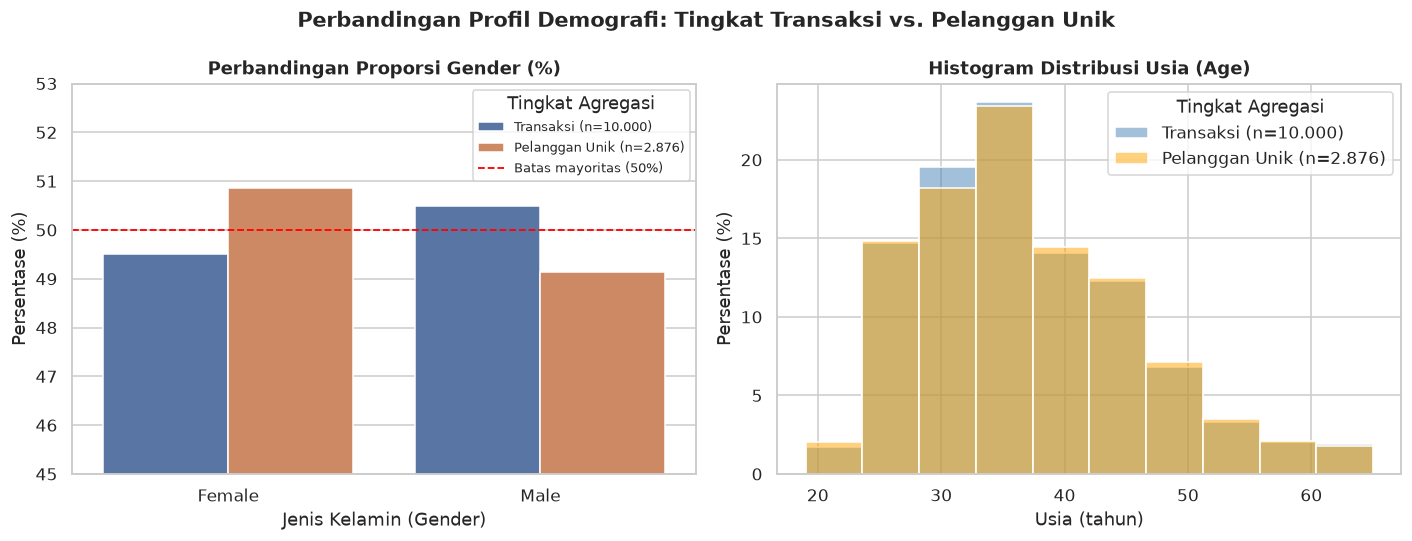

In [16]:
# Diagram perbandingan proporsi Gender dan histogram distribusi Age
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_gender = pd.DataFrame({
    'Gender': ['Female', 'Male', 'Female', 'Male'],
    'Persentase': [gender_trx['Female'], gender_trx['Male'], gender_cust['Female'], gender_cust['Male']],
    'Level': ['Transaksi (n=10.000)', 'Transaksi (n=10.000)', 'Pelanggan Unik (n=2.876)', 'Pelanggan Unik (n=2.876)']
})
sns.barplot(data=plot_gender, x='Gender', y='Persentase', hue='Level', ax=axes[0])
axes[0].axhline(50, color='red', linestyle='--', linewidth=1.2, label='Batas mayoritas (50%)')
axes[0].set_ylim(45, 53)
axes[0].set_title('Perbandingan Proporsi Gender (%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jenis Kelamin (Gender)')
axes[0].set_ylabel('Persentase (%)')
axes[0].legend(title='Tingkat Agregasi', loc='upper right', fontsize=8.5)

sns.histplot(df_raw['Age'], stat='percent', bins=10, color='steelblue', alpha=0.5,
             label='Transaksi (n=10.000)', ax=axes[1])
sns.histplot(df_pelanggan['Age'], stat='percent', bins=10, color='orange', alpha=0.5,
             label='Pelanggan Unik (n=2.876)', ax=axes[1])
axes[1].set_title('Histogram Distribusi Usia (Age)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Usia (tahun)')
axes[1].set_ylabel('Persentase (%)')
axes[1].legend(title='Tingkat Agregasi')

fig.suptitle('Perbandingan Profil Demografi: Tingkat Transaksi vs. Pelanggan Unik', fontsize=13.5, fontweight='bold')
plt.tight_layout()
plt.savefig('charts/A_granularitas_demografi.png', dpi=300, bbox_inches='tight')
plt.show()

**Insight Grafik A.3 (Dampak Granularitas pada Demografi).** Mayoritas gender berbalik arah antara dua tingkat agregasi: pada tingkat pelanggan unik ($n = 2.876$) mayoritas adalah **Female (50,87%)**, sedangkan pada tingkat transaksi ($n = 10.000$) **Male tampak dominan (50,49%)** akibat rata-rata frekuensi belanja pelanggan pria lebih tinggi (3,57 vs. 3,38 transaksi/orang, termasuk `CUST-00679` dengan 137 transaksi). Pada histogram usia, pembobotan *repeat buyer* menggeser modus usia dari 35 tahun menjadi 32 tahun dan sedikit menurunkan rata-rata usia (36,96 menjadi 36,91 tahun). Secara bisnis, agregasi tingkat pelanggan unik wajib digunakan untuk menyusun segmentasi profil pelanggan, sedangkan tingkat transaksi tepat untuk mengukur porsi volume penjualan tiap segmen.

## A.4 Kesimpulan Bagian A
1. **A.1 (Klasifikasi Variabel):** Seluruh 19 kolom terklasifikasi sesuai deskripsi dataset ke 6 tipe statistik (`Identifier`: 2, `Nominal`: 7, `Ordinal`: 3, `Diskrit`: 3, `Kontinu`: 3, `Temporal`: 1) dan dikelompokkan dalam sheet terpisah pada `TugasBagianA_Kelompok.xlsx`.
2. **A.2 (Audit Kualitas Data):** Secara struktural dataset memiliki `0` missing value (`isnull().sum()`), `0` baris duplikat (`duplicated().sum()`), `0` duplikat `Transaction_ID`, dan `0` inkonsistensi rumus matematis `Purchase_Amount`. Transaksi `Cash` pada kanal daring (`349` baris) tetap dipertahankan karena valid sebagai COD (*Cash on Delivery*). Perbaikan pada `TugasBagianA_Bersih.xlsx` mencakup standardisasi tipe penyimpanan CSV (`Purchase_Date` ke format tanggal asli, angka `.0` ke bilangan bulat) serta pemisahan **443 baris anomali operasional gerai fisik** (`437` transaksi gerai fisik pada jam `00:00` s.d. `07:00` dan `23:00`, serta `6` baris konflik 2 gerai fisik berbeda pada tanggal dan jam yang sama), menghasilkan **9.557 baris data bersih**.
3. **A.3 (Pelanggan Unik vs. Transaksi):** Perbedaan hasil disebabkan oleh pembobotan frekuensi transaksi ulang (`2.876` pelanggan unik menghasilkan `10.000` transaksi, rata rata `3,48` transaksi/pelanggan, maksimum `137` transaksi). Pada tingkat transaksi, mayoritas Gender tampak **Male (50,49%)** dan modus usia bergeser ke **32 tahun**, padahal pada tingkat pelanggan unik mayoritas sebenarnya adalah **Female (50,87%)** dengan rata rata usia **36,96 tahun** (median 36, modus 35). Metrik yang lebih valid untuk menggambarkan profil demografi pelanggan adalah **tingkat pelanggan unik (`n = 2.876`)**.

# BAGIAN B: Statistik Deskriptif dan Evaluasi Outlier (Bobot: 35%)

**Basis data utama:** `Data_Bersih` dari `TugasBagianA_Bersih.xlsx` (**9.557 transaksi**), selaras dengan analisis Bagian C sehingga seluruh angka pemusatan, penyebaran, outlier, dan visualisasi mengacu pada populasi transaksi yang sama (`Discount_Percentage` dalam skala `0–50%`).  
**Data pembanding:** Dataset mentah `customer_behavior_phase1.csv` (`df_raw`, **10.000 transaksi**) ditampilkan pada tabel pembanding di B.1 dan B.3 untuk mengonfirmasi bahwa pembersihan 443 baris anomali operasional gerai fisik di Bagian A tidak mengubah pola statistik utama.

## B.0 Validasi Basis Data Utama dan Pembanding

In [17]:
print('Data utama (Data_Bersih)  :', df.shape, '| Missing:', df.isnull().sum().sum())
print('Data pembanding (Mentah)  :', df_raw.shape, '| Missing:', df_raw.isnull().sum().sum())

# Validasi rumus Purchase_Amount = Quantity * Unit_Price * (1 - Discount_Percentage/100)
for nama, d in [('Data Bersih (utama)', df), ('Data Mentah (pembanding)', df_raw)]:
    hitung = d['Quantity'] * d['Unit_Price'] * (1 - d['Discount_Percentage'] / 100)
    print(f'Selisih rumus {nama}: {(~np.isclose(hitung, d["Purchase_Amount"])).sum()} baris')

Data utama (Data_Bersih)  : (9557, 21) | Missing: 0
Data pembanding (Mentah)  : (10000, 19) | Missing: 0
Selisih rumus Data Bersih (utama): 0 baris
Selisih rumus Data Mentah (pembanding): 0 baris


## B.1 Ukuran Pemusatan dan Penyebaran

Rumus yang dipakai setara fungsi Excel: `STDEV.S` (`ddof=1`), `QUARTILE.INC` (interpolasi linear, default pandas), dan `SKEW` (skewness sampel, default `pandas.skew()`). `Discount_Percentage` disajikan dalam persen (`0–50%`).

In [18]:
variabel = ['Purchase_Amount', 'Quantity', 'Unit_Price', 'Discount_Percentage']

def statistik(d):
    s = d[variabel]
    return pd.DataFrame({
        'Mean': s.mean(), 'Median': s.median(), 'Std Dev': s.std(),
        'Q1': s.quantile(.25), 'Q3': s.quantile(.75),
        'IQR': s.quantile(.75) - s.quantile(.25),
        'Min': s.min(), 'Max': s.max(), 'Skewness': s.skew()
    })

print('DATA BERSIH (n = 9.557) — tabel utama (selaras dengan Bagian C)')
stat_bersih = statistik(df)
display(stat_bersih)

print('DATA MENTAH (n = 10.000) — tabel pembanding')
stat_mentah = statistik(df_raw)
display(stat_mentah)

DATA BERSIH (n = 9.557) — tabel utama (selaras dengan Bagian C)


,Mean,Median,Std Dev,Q1,Q3,IQR,Min,Max,Skewness
Purchase_Amount,"1,993,255.90","478,500.00","10,364,523.75","219,300.00","1,164,000.00","944,700.00","25,650.00","251,351,100.00",14.39
Quantity,3.26,2.00,3.95,1.00,4.00,3.00,1.00,55.00,7.23
Unit_Price,"514,453.91","214,000.00","1,180,794.53","118,000.00","457,000.00","339,000.00","25,000.00","18,304,000.00",8.86
Discount_Percentage,10.52,10.00,10.72,0.00,15.00,15.00,0.00,50.00,1.31


DATA MENTAH (n = 10.000) — tabel pembanding


,Mean,Median,Std Dev,Q1,Q3,IQR,Min,Max,Skewness
Purchase_Amount,"1,983,001.00","477,000.00","10,323,960.75","218,875.00","1,158,250.00","939,375.00","25,650.00","251,351,100.00",14.39
Quantity,3.25,2.00,3.90,1.00,4.00,3.00,1.00,55.00,7.23
Unit_Price,"514,159.30","214,000.00","1,182,279.97","118,000.00","455,000.00","337,000.00","25,000.00","18,304,000.00",8.80
Discount_Percentage,10.49,10.00,10.69,0.00,15.00,15.00,0.00,50.00,1.31


Pada data utama (`Data_Bersih`, $n = 9.557$), `Purchase_Amount` memiliki mean (**Rp 1.993.255,90**) yang jauh di atas median (**Rp 478.500,00**) dan skewness **14,39**, menandakan ekor kanan yang sangat panjang. `Quantity` (skewness **7,23**, mean 3,26 vs. median 2,00) dan `Unit_Price` (skewness **8,86**, mean Rp 514.453,91 vs. median Rp 214.000,00) juga condong ke kanan secara kuat. `Discount_Percentage` miring kanan moderat (skewness **1,31**, mean **10,52%**, median **10,00%**), karena sebagian besar transaksi mendapat diskon kecil atau tanpa diskon (`Q1 = 0%`, `Q3 = 15%`). Perbandingan dengan data mentah ($n = 10.000$) menghasilkan angka yang hampir identik (mis. median `Purchase_Amount` Rp 477.000 vs. Rp 478.500; skewness sama-sama 14,39), membuktikan pembersihan Bagian A tidak mengubah karakteristik statistik dataset.

## B.2 Interpretasi Distribusi: `Purchase_Amount` dan `Age`

,Mean,Median,Skewness,Mean / Median
Purchase_Amount,"1,993,255.90","478,500.00",14.39,4.17
Age,36.90,35.00,0.84,1.05


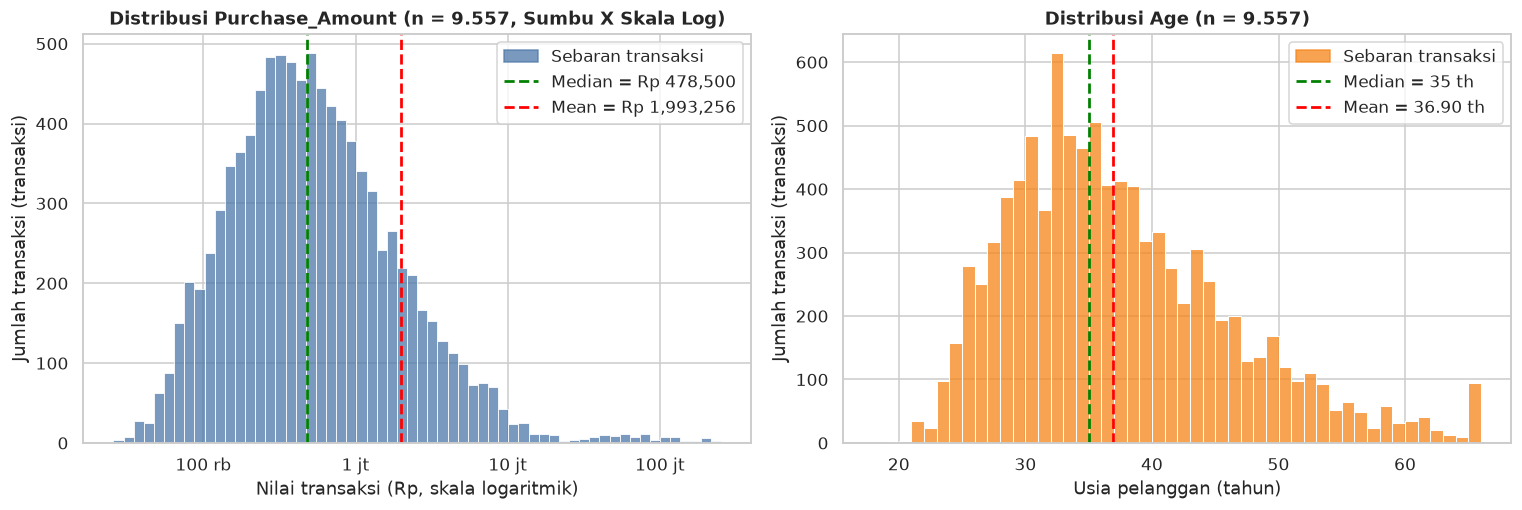

In [19]:
dist = pd.DataFrame({
    'Mean': df[['Purchase_Amount', 'Age']].mean(),
    'Median': df[['Purchase_Amount', 'Age']].median(),
    'Skewness': df[['Purchase_Amount', 'Age']].skew()
})
dist['Mean / Median'] = dist['Mean'] / dist['Median']
display(dist)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))

# Purchase_Amount: skala log agar bentuk distribusi terlihat
sns.histplot(df['Purchase_Amount'], bins=60, log_scale=True, color='#4c78a8', ax=ax[0])
ax[0].axvline(df['Purchase_Amount'].median(), color='green', ls='--', linewidth=1.8,
              label=f"Median = Rp {df['Purchase_Amount'].median():,.0f}")
ax[0].axvline(df['Purchase_Amount'].mean(), color='red', ls='--', linewidth=1.8,
              label=f"Mean = Rp {df['Purchase_Amount'].mean():,.0f}")
ax[0].xaxis.set_major_formatter(FuncFormatter(rp_singkat))
ax[0].set_title('Distribusi Purchase_Amount (n = 9.557, Sumbu X Skala Log)', fontweight='bold')
ax[0].set_xlabel('Nilai transaksi (Rp, skala logaritmik)')
ax[0].set_ylabel('Jumlah transaksi (transaksi)')
h0, l0 = ax[0].get_legend_handles_labels()
ax[0].legend(handles=[Patch(color='#4c78a8', alpha=0.75, label='Sebaran transaksi')] + h0)

sns.histplot(df['Age'], bins=range(18, 67), color='#f58518', ax=ax[1])
ax[1].axvline(df['Age'].median(), color='green', ls='--', linewidth=1.8,
              label=f"Median = {df['Age'].median():.0f} th")
ax[1].axvline(df['Age'].mean(), color='red', ls='--', linewidth=1.8,
              label=f"Mean = {df['Age'].mean():.2f} th")
ax[1].set_title('Distribusi Age (n = 9.557)', fontweight='bold')
ax[1].set_xlabel('Usia pelanggan (tahun)')
ax[1].set_ylabel('Jumlah transaksi (transaksi)')
h1, l1 = ax[1].get_legend_handles_labels()
ax[1].legend(handles=[Patch(color='#f58518', alpha=0.75, label='Sebaran transaksi')] + h1)

plt.tight_layout()
plt.savefig('charts/B_distribusi_amount_age.png', dpi=300, bbox_inches='tight')
plt.show()

**Interpretasi & Insight Grafik B.2:**

- **`Purchase_Amount`: miring positif (*right-skewed*) sangat ekstrem.** Mean (**Rp 1.993.256**) sekitar **4,17 kali** median (**Rp 478.500**) dengan skewness **14,39** (jauh di atas +1). Sejumlah kecil transaksi bernilai puluhan hingga ratusan juta menarik mean jauh ke kanan, sedangkan 75% transaksi berada di bawah Rp 1,16 juta (`Q3 = Rp 1.164.000`).
- **`Age`: miring positif ringan-sedang.** Mean (**36,90 tahun**) sedikit di atas median (**35,00 tahun**) dan skewness **0,84**. Seperti dicatat pada audit **Bagian A.2**, ekor kanan distribusi usia dipengaruhi penumpukan tepat di batas atas `Age = 65` (100 transaksi pada data mentah dibanding hanya 10 transaksi di usia 64), namun mean dan median tetap berdekatan sehingga keduanya informatif.
- **Metrik yang paling tepat mewakili nilai belanja tipikal pelanggan: MEDIAN (Rp 478.500).** Alasan: (1) mean tidak mewakili mayoritas pelanggan karena **84,9%** transaksi berada di bawah nilai mean (lihat sel di bawah); (2) mean sangat sensitif terhadap transaksi ekstrem (berubah **−45,0%** saat transaksi mencurigakan disisihkan pada B.3.3), sedangkan median jauh lebih stabil (hanya bergeser **−2,2%**). Mean tetap relevan dipakai untuk menghitung **total omzet** (total = mean × n), bukan untuk menggambarkan "belanja tipikal".

In [20]:
print(f"Persentase transaksi di bawah mean Purchase_Amount (Data Bersih): {(df['Purchase_Amount'] < df['Purchase_Amount'].mean()).mean()*100:.1f}%")

Persentase transaksi di bawah mean Purchase_Amount (Data Bersih): 84.9%


## B.3 Deteksi dan Evaluasi Outlier (Metode IQR)

Batas bawah = $Q1 - 1{,}5 \times IQR$ dan batas atas = $Q3 + 1{,}5 \times IQR$, dihitung pada basis data utama (`Data_Bersih`, **9.557 transaksi**), disertai tabel pembanding pada data mentah (**10.000 transaksi**).

In [21]:
def ringkas_iqr(d):
    baris = []
    for k in ['Purchase_Amount', 'Quantity']:
        q1, q3, iqr, lo, hi = batas_iqr(d[k])
        n_lo, n_hi = int((d[k] < lo).sum()), int((d[k] > hi).sum())
        baris.append({
            'Variabel': k, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
            'Batas Bawah': lo, 'Batas Atas': hi,
            'Outlier Bawah': n_lo, 'Outlier Atas': n_hi,
            'Total Outlier': n_lo + n_hi,
            'Persentase (%)': (n_lo + n_hi) / len(d) * 100
        })
    return pd.DataFrame(baris)

print('DETEKSI OUTLIER IQR — DATA BERSIH (n = 9.557, basis utama)')
tabel_iqr = ringkas_iqr(df)
display(tabel_iqr)

LO_A, HI_A = batas_iqr(df['Purchase_Amount'])[3:]
LO_Q, HI_Q = batas_iqr(df['Quantity'])[3:]
df['out_amt'] = (df['Purchase_Amount'] < LO_A) | (df['Purchase_Amount'] > HI_A)
df['out_qty'] = (df['Quantity'] < LO_Q) | (df['Quantity'] > HI_Q)

print('Outlier gabungan (salah satu):', int((df['out_amt'] | df['out_qty']).sum()),
      '| keduanya:', int((df['out_amt'] & df['out_qty']).sum()))
tot = df['Purchase_Amount'].sum()
print(f"Outlier Purchase_Amount = {df['out_amt'].mean()*100:.2f}% transaksi, tetapi menyumbang {df.loc[df['out_amt'], 'Purchase_Amount'].sum()/tot*100:.1f}% total omzet (Rp {tot/1e9:.2f} M)")

print('\nPEMBANDING — DATA MENTAH (n = 10.000)')
display(ringkas_iqr(df_raw))

DETEKSI OUTLIER IQR — DATA BERSIH (n = 9.557, basis utama)


,Variabel,Q1,Q3,IQR,Batas Bawah,Batas Atas,Outlier Bawah,Outlier Atas,Total Outlier,Persentase (%)
0,Purchase_Amount,"219,300.00","1,164,000.00","944,700.00","-1,197,750.00","2,581,050.00",0,1084,1084,11.34
1,Quantity,1.00,4.00,3.00,-3.50,8.50,0,367,367,3.84


Outlier gabungan (salah satu): 1261 | keduanya: 190
Outlier Purchase_Amount = 11.34% transaksi, tetapi menyumbang 73.0% total omzet (Rp 19.05 M)

PEMBANDING — DATA MENTAH (n = 10.000)


,Variabel,Q1,Q3,IQR,Batas Bawah,Batas Atas,Outlier Bawah,Outlier Atas,Total Outlier,Persentase (%)
0,Purchase_Amount,"218,875.00","1,158,250.00","939,375.00","-1,190,187.50","2,567,312.50",0,1126,1126,11.26
1,Quantity,1.00,4.00,3.00,-3.50,8.50,0,386,386,3.86


Batas bawah kedua variabel bernilai negatif, sedangkan nilai minimum `Purchase_Amount` adalah Rp 25.650 dan `Quantity` minimum 1, sehingga **tidak ada outlier bawah**; seluruh outlier berada di sisi atas. Pada `Data_Bersih` ($n = 9.557$), terdapat **1.084 outlier `Purchase_Amount` (11,34%)** yang menyumbang **73,0%** total omzet dan **367 outlier `Quantity` (3,84%)**; gabungannya berjumlah **1.261 transaksi** (190 transaksi menjadi outlier pada keduanya). Angka ini konsisten dengan data mentah pembanding (1.126 outlier `Purchase_Amount` atau 11,26% dan 386 outlier `Quantity` atau 3,86%).

### B.3.1 Karakteristik Outlier: Produk, Kuantitas, dan Tier Membership

In [22]:
out = df[df['out_amt'] | df['out_qty']].copy()

# a) Produk / kategori: jumlah outlier DAN proporsi terhadap seluruh transaksi kategori itu
kat = df.groupby('Product_Category').agg(
    Total_Trx=('Transaction_ID', 'size'),
    Outlier_Amount=('out_amt', 'sum'),
    Outlier_Qty=('out_qty', 'sum')
)
kat['% Outlier Amount'] = kat['Outlier_Amount'] / kat['Total_Trx'] * 100
kat['% Outlier Qty'] = kat['Outlier_Qty'] / kat['Total_Trx'] * 100
display(kat.sort_values('Outlier_Amount', ascending=False))

# b) Produk spesifik pada outlier Purchase_Amount
display(df[df['out_amt']]['Product_Name'].value_counts().head(8).rename('Jumlah outlier Amount').to_frame())

# c) Membership: bandingkan PROPORSI dalam tiap tier serta median belanja
urut = ['Basic', 'Silver', 'Gold', 'Premium']
mem = df.groupby('Membership_Level').agg(
    Total_Trx=('Transaction_ID', 'size'),
    Outlier_Amount=('out_amt', 'sum'),
    Outlier_Qty=('out_qty', 'sum'),
    Median_Amount=('Purchase_Amount', 'median')
).reindex(urut)
mem['% Outlier Amount'] = mem['Outlier_Amount'] / mem['Total_Trx'] * 100
mem['% Outlier Qty'] = mem['Outlier_Qty'] / mem['Total_Trx'] * 100
display(mem)

,Total_Trx,Outlier_Amount,Outlier_Qty,% Outlier Amount,% Outlier Qty
Product_Category,,,,,
Electronics,1774,855,66,48.20,3.72
Home & Living,1902,128,82,6.73,4.31
Fashion,2107,70,85,3.32,4.03
Beauty & Health,1906,16,66,0.84,3.46
Groceries,1868,15,68,0.80,3.64


,Jumlah outlier Amount
Product_Name,
Noise Cancelling Headphones,162
Smartwatch Pro,161
27-Inch Monitor,157
Bluetooth Speaker,138
Wireless Earbuds,129
Mechanical Keyboard,108
Air Purifier Mini,32
Ergonomic Desk Lamp,29


,Total_Trx,Outlier_Amount,Outlier_Qty,Median_Amount,% Outlier Amount,% Outlier Qty
Membership_Level,,,,,,
Basic,4033,365,144,"440,300.00",9.05,3.57
Silver,2647,272,110,"412,500.00",10.28,4.16
Gold,1919,259,68,"532,000.00",13.50,3.54
Premium,958,188,45,"817,950.00",19.62,4.70


**Temuan:**
- **Produk:** **855 dari 1.084** outlier `Purchase_Amount` (**78,9%**) berasal dari kategori **Electronics**, dan **48,2%** dari seluruh transaksi Electronics melewati batas atas IQR global. Artinya Electronics memang memiliki tingkat harga yang jauh lebih tinggi dibanding kategori lain, sehingga sebagian besar "outlier" menurut IQR global merupakan transaksi normal untuk kategori mahal, bukan anomali data.
- **Membership:** Jika dilihat dari jumlah absolut, Basic tampak memiliki outlier terbanyak (365 transaksi) karena porsinya memang paling besar (**42,2%** dari total transaksi bersih). Secara **proporsional** dalam tiap tier, persentase outlier `Purchase_Amount` meningkat berurutan: **Premium 19,6%**, **Gold 13,5%**, **Silver 10,3%**, dan **Basic 9,1%**. **Namun**, tingginya porsi ekor atas tidak berarti semua tier tinggi memiliki belanja tipikal lebih besar: median transaksi **Silver (Rp 412.500)** justru sedikit lebih rendah daripada **Basic (Rp 440.300)**, sementara baru **Gold (Rp 532.000)** dan **Premium (Rp 817.950)** yang meningkat signifikan—temuan ini selaras penuh dengan **Grafik 3.1 pada Bagian C**. Sebaliknya, proporsi outlier `Quantity` relatif merata di semua tier (**3,5% s.d. 4,7%**), sehingga kuantitas ekstrem tidak dipengaruhi tier keanggotaan.
- Menggunakan rata-rata nilai outlier per tier akan menyesatkan, karena angkanya didominasi beberapa transaksi bernilai ratusan juta rupiah.

### B.3.2 Pemeriksaan Kewajaran Outlier: Dua Pola yang Mencurigakan

IQR hanya menandai nilai yang jauh dari pusat distribusi, bukan membuktikan apakah nilai tersebut **salah**. Dua pemeriksaan lanjutan pada `Data_Bersih` mengungkap pola berikut:
1. **`Quantity`:** Sebaran `Quantity` memiliki celah (*gap*) yang tegas: nilai 1 s.d. 10 unit terisi rapat, lalu **tidak ada satu pun transaksi dengan Quantity 11 s.d. 14**, sebelum muncul **93 transaksi** dengan Quantity 15 s.d. 55. Batas IQR (8,5) memotong di tengah ekor yang wajar (Quantity 9 dan 10 ikut tertandai padahal masih bagian dari pola normal).
2. **`Unit_Price`:** Harga satuan satu produk seharusnya relatif stabil, tetapi beberapa produk bervariasi tidak wajar (misalnya *Organic Honey Jar* tercatat hingga **Rp 8,56 juta/unit** dan *Arabica Coffee Beans 500g* hingga **Rp 8,42 juta/unit**, padahal median harga kedua produk itu hanya sekitar **Rp 90–91 ribu**).

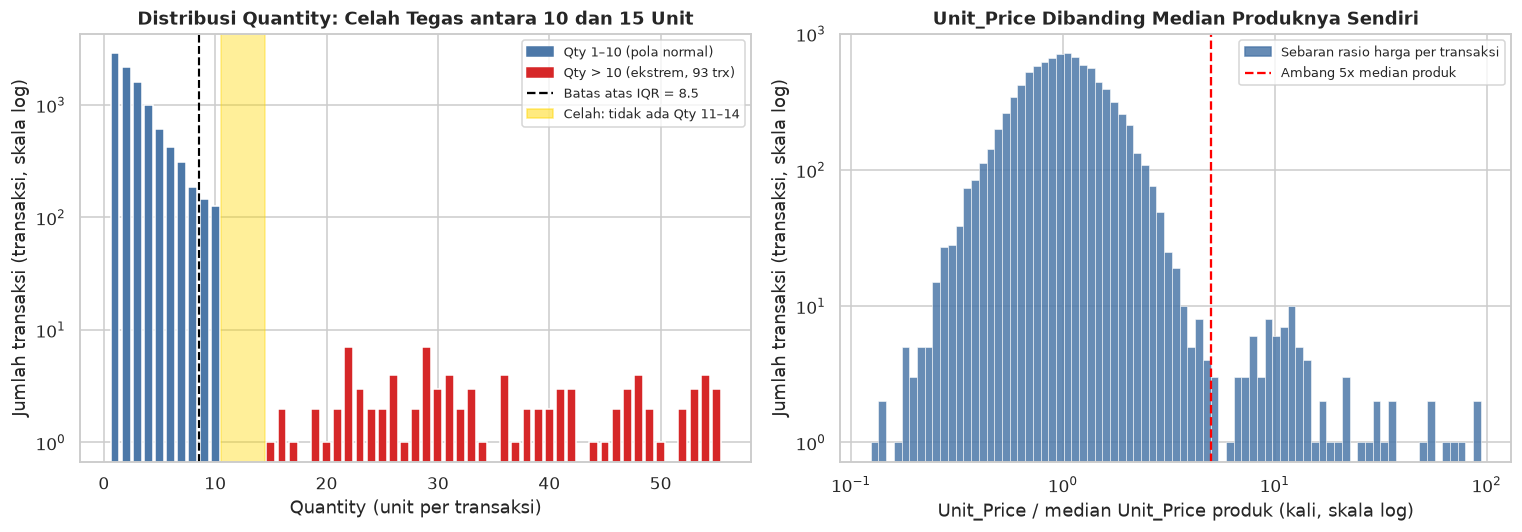

Quantity > 10            : 93 baris | rata-rata Qty = 35.0 (vs median Qty normal = 2)
Harga > 5x median produk : 82 baris
Irisan keduanya          : 27 | gabungan baris mencurigakan: 148

Sebaran Quantity > 10 per kategori : {'Home & Living': 25, 'Groceries': 19, 'Electronics': 19, 'Beauty & Health': 17, 'Fashion': 13}
Sebaran Harga > 5x per kategori    : {'Electronics': 58, 'Fashion': 8, 'Home & Living': 7, 'Groceries': 6, 'Beauty & Health': 3}
Sensitivitas ambang harga (baris)  : 4x = 96 | 5x = 82 | 6x = 78
Contoh Organic Honey Jar         : median Rp 91,000 | maks Rp 8,561,000
Contoh Arabica Coffee Beans 500g : median Rp 90,000 | maks Rp 8,416,000
Contoh Air Purifier Mini         : median Rp 323,000 | maks Rp 9,009,000


In [23]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

vc = df['Quantity'].value_counts().reindex(range(1, 56), fill_value=0)
ax[0].bar(vc.index, vc.values, color=['#4c78a8' if q <= 10 else '#d62728' for q in vc.index])
ax[0].axvline(HI_Q, color='black', ls='--', linewidth=1.4)
ax[0].axvspan(10.5, 14.5, color='gold', alpha=0.4)
ax[0].set_title('Distribusi Quantity: Celah Tegas antara 10 dan 15 Unit', fontweight='bold')
ax[0].set_xlabel('Quantity (unit per transaksi)')
ax[0].set_ylabel('Jumlah transaksi (transaksi, skala log)')
ax[0].set_yscale('log')
ax[0].legend(handles=[
    Patch(color='#4c78a8', label='Qty 1–10 (pola normal)'),
    Patch(color='#d62728', label='Qty > 10 (ekstrem, 93 trx)'),
    Line2D([0], [0], color='black', ls='--', label=f'Batas atas IQR = {HI_Q}'),
    Patch(color='gold', alpha=0.5, label='Celah: tidak ada Qty 11–14'),
], loc='upper right', fontsize=8.5)

df['Median_Harga_Produk'] = df.groupby('Product_Name')['Unit_Price'].transform('median')
df['Rasio_Harga'] = df['Unit_Price'] / df['Median_Harga_Produk']
bins_rasio = np.logspace(np.log10(df['Rasio_Harga'].min()), np.log10(df['Rasio_Harga'].max()), 80)
ax[1].hist(df['Rasio_Harga'], bins=bins_rasio, log=True, color='#4c78a8', alpha=0.85,
           edgecolor='white', linewidth=0.4)
ax[1].set_xscale('log')
ax[1].axvline(5, color='red', ls='--', linewidth=1.5)
ax[1].set_title('Unit_Price Dibanding Median Produknya Sendiri', fontweight='bold')
ax[1].set_xlabel('Unit_Price / median Unit_Price produk (kali, skala log)')
ax[1].set_ylabel('Jumlah transaksi (transaksi, skala log)')
ax[1].legend(handles=[
    Patch(color='#4c78a8', alpha=0.85, label='Sebaran rasio harga per transaksi'),
    Line2D([0], [0], color='red', ls='--', label='Ambang 5x median produk'),
], loc='upper right', fontsize=8.5)

plt.tight_layout()
plt.savefig('charts/B_pola_anomali_qty_harga.png', dpi=300, bbox_inches='tight')
plt.show()

df['qty_ekstrem'] = df['Quantity'] > 10
df['harga_ekstrem'] = df['Rasio_Harga'] > 5
df['mencurigakan'] = df['qty_ekstrem'] | df['harga_ekstrem']

print('Quantity > 10            :', int(df['qty_ekstrem'].sum()), 'baris | rata-rata Qty =',
      round(df.loc[df['qty_ekstrem'], 'Quantity'].mean(), 1), '(vs median Qty normal = 2)')
print('Harga > 5x median produk :', int(df['harga_ekstrem'].sum()), 'baris')
print('Irisan keduanya          :', int((df['qty_ekstrem'] & df['harga_ekstrem']).sum()),
      '| gabungan baris mencurigakan:', int(df['mencurigakan'].sum()))
print()
print('Sebaran Quantity > 10 per kategori :', df[df['qty_ekstrem']]['Product_Category'].value_counts().to_dict())
print('Sebaran Harga > 5x per kategori    :', df[df['harga_ekstrem']]['Product_Category'].value_counts().to_dict())
print('Sensitivitas ambang harga (baris)  : 4x =', int((df['Rasio_Harga'] > 4).sum()),
      '| 5x =', int((df['Rasio_Harga'] > 5).sum()),
      '| 6x =', int((df['Rasio_Harga'] > 6).sum()))
for prod in ['Organic Honey Jar', 'Arabica Coffee Beans 500g', 'Air Purifier Mini']:
    sub_p = df[df['Product_Name'] == prod]
    print(f"Contoh {prod:26s}: median Rp {sub_p['Unit_Price'].median():,.0f} | maks Rp {sub_p['Unit_Price'].max():,.0f}")

**Insight Grafik B.3.2 (Pola Anomali Kuantitas & Harga Satuan).** Grafik kiri memperlihatkan celah (*gap*) yang tegas pada rentang `Quantity = 11–14`, memisahkan pola belanja normal (1–10 unit) dari **93 transaksi** bernilai 15–55 unit (rata-rata **35,0 unit**) yang tersebar di seluruh lima kategori produk. Grafik kanan menunjukkan rasio `Unit_Price` terhadap median produk masing-masing umumnya berkumpul di kisaran 1× hingga 4×, lalu melonjak menjadi ekor panjang ekstrem sebanyak **82 transaksi** di atas ambang 5× (**58 di Electronics**, namun juga mencakup lonjakan harga yang tidak masuk akal pada Groceries). Secara bisnis, gabungan kedua indikator ini memisahkan **148 transaksi mencurigakan** (dengan 27 baris tumpang tindih) untuk diaudit sebelum diperlakukan sebagai pendapatan ritel reguler.

**Catatan metodologis tentang ambang 5×:** Angka 5× adalah heuristik berbasis inspeksi visual sebaran rasio harga, bukan aturan baku statistik. Uji sensitivitas di atas menunjukkan jumlah baris yang terjaring cukup stabil di sekitar ambang tersebut (**96 / 82 / 78 baris** pada ambang 4× / 5× / 6×). Karena dataset tidak memuat log transaksi kasir ataupun penanda pesanan korporat, analisis data **tidak dapat membuktikan** apakah 148 baris ini murni kesalahan input atau pembelian grosir khusus—sehingga statusnya ditetapkan sebagai **"perlu diverifikasi"**, bukan dihapus sepihak.

,Jumlah,Total_Omzet,Median_Amount,% dari 9.557 trx,% dari total omzet
Segmen,,,,,
A. Wajar (produk mahal / multi-unit normal),1114,5409787650,"3,844,800.00",11.66,28.40
B. Quantity ekstrem (>10),66,1317543050,"7,195,500.00",0.69,6.92
C. Qty>10 DAN harga ekstrem,27,4267982700,"142,015,500.00",0.28,22.40
D. Harga satuan ekstrem (>5x median produk),54,3149394200,"53,785,250.00",0.57,16.53


Baris mencurigakan (B+C+D) di luar outlier IQR: 1
Total seluruh 148 baris mencurigakan: Rp 8.74 M (45.9% total omzet)
Transaksi terbesar: TRX-000062 | Air Purifier Mini | Qty 31 x Rp 9,009,000 = Rp 251,351,100


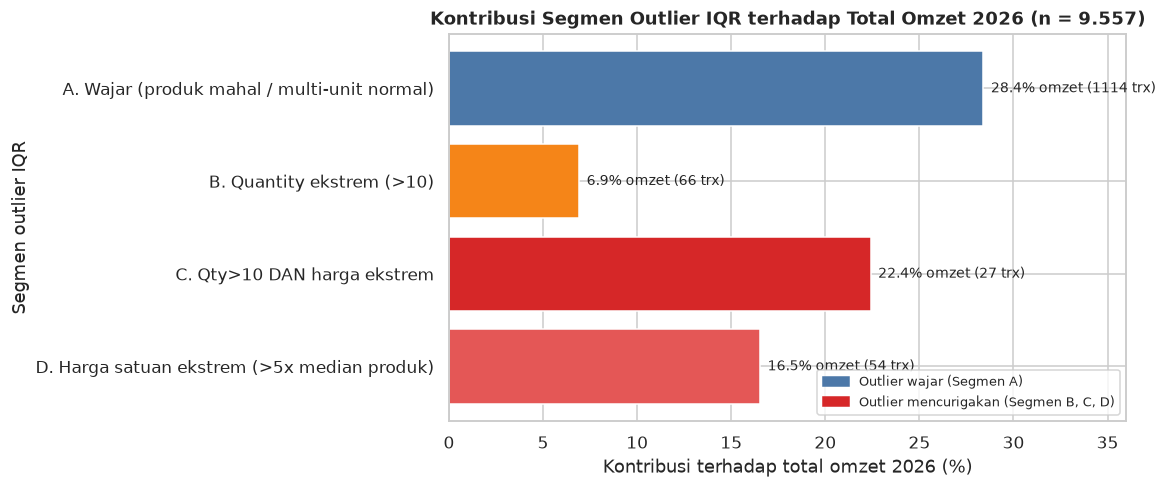

In [24]:
# Segmentasi outlier IQR menjadi 4 segmen pada Data Bersih
def segmen(r):
    if r['qty_ekstrem'] and r['harga_ekstrem']:
        return 'C. Qty>10 DAN harga ekstrem'
    if r['qty_ekstrem']:
        return 'B. Quantity ekstrem (>10)'
    if r['harga_ekstrem']:
        return 'D. Harga satuan ekstrem (>5x median produk)'
    return 'A. Wajar (produk mahal / multi-unit normal)'

o = df[df['out_amt'] | df['out_qty']].copy()
o['Segmen'] = o.apply(segmen, axis=1)

seg = o.groupby('Segmen').agg(
    Jumlah=('Transaction_ID', 'size'),
    Total_Omzet=('Purchase_Amount', 'sum'),
    Median_Amount=('Purchase_Amount', 'median')
)
seg['% dari 9.557 trx'] = seg['Jumlah'] / len(df) * 100
seg['% dari total omzet'] = seg['Total_Omzet'] / df['Purchase_Amount'].sum() * 100
display(seg)

sus_all = df[df['mencurigakan']]
sus_outside = int(df['mencurigakan'].sum()) - int((o['Segmen'] != 'A. Wajar (produk mahal / multi-unit normal)').sum())
print('Baris mencurigakan (B+C+D) di luar outlier IQR:', sus_outside)
print(f"Total seluruh 148 baris mencurigakan: Rp {sus_all['Purchase_Amount'].sum()/1e9:.2f} M "
      f"({sus_all['Purchase_Amount'].sum()/df['Purchase_Amount'].sum()*100:.1f}% total omzet)")
top_row = df.loc[df['Purchase_Amount'].idxmax()]
print(f"Transaksi terbesar: {top_row['Transaction_ID']} | {top_row['Product_Name']} | "
      f"Qty {top_row['Quantity']} x Rp {top_row['Unit_Price']:,.0f} = Rp {top_row['Purchase_Amount']:,.0f}")

fig, ax = plt.subplots(figsize=(10.5, 4.6))
s = seg.sort_index()
warna_seg = ['#4c78a8', '#f58518', '#d62728', '#e45756']
ax.barh(s.index, s['% dari total omzet'], color=warna_seg)
for i, (v, n) in enumerate(zip(s['% dari total omzet'], s['Jumlah'])):
    ax.text(v + 0.4, i, f'{v:.1f}% omzet ({n} trx)', va='center', fontsize=9)
ax.set_xlim(0, 36)
ax.invert_yaxis()
ax.set_title('Kontribusi Segmen Outlier IQR terhadap Total Omzet 2026 (n = 9.557)', fontweight='bold')
ax.set_xlabel('Kontribusi terhadap total omzet 2026 (%)')
ax.set_ylabel('Segmen outlier IQR')
ax.legend(handles=[
    Patch(color='#4c78a8', label='Outlier wajar (Segmen A)'),
    Patch(color='#d62728', label='Outlier mencurigakan (Segmen B, C, D)'),
], loc='lower right', fontsize=8.5)
plt.tight_layout()
plt.savefig('charts/B_kontribusi_segmen_outlier.png', dpi=300, bbox_inches='tight')
plt.show()

**Insight Grafik B.3.3 (Segmentasi Nilai Outlier).** Dari **1.261** transaksi outlier IQR, sebanyak **1.114 transaksi (88,3%) tergolong wajar** (Segmen A: produk elektronik mahal atau pembelian multi-unit normal, menyumbang **28,4%** omzet), sedangkan **147 transaksi** di dalam outlier IQR (plus **1 baris** mencurigakan di luar batas IQR; total **148 baris** atau **1,55%** data) berstatus mencurigakan. Ironisnya, **148 transaksi mencurigakan** inilah yang menyumbang **Rp 8,74 miliar** atau **45,9% total omzet** (`Rp 19,05 miliar`). Satu transaksi terbesar saja—*Air Purifier Mini* sebanyak 31 unit seharga Rp 9.009.000/unit (padahal median produknya Rp 323 ribu) dengan total **Rp 251.351.100**—setara dengan omzet sekitar **525 transaksi tipikal** (median Rp 478.500).

### B.3.3 Uji Sensitivitas: Seberapa Besar Baris Mencurigakan Memengaruhi Statistik?

In [25]:
versi = {
    'Semua Data Bersih (9.557)': df,
    'Tanpa 148 Baris Mencurigakan (9.409)': df[~df['mencurigakan']]
}
rows = []
for nama, d in versi.items():
    rows.append({
        'Versi': nama, 'n': len(d),
        'Mean': d['Purchase_Amount'].mean(),
        'Median': d['Purchase_Amount'].median(),
        'Std Dev': d['Purchase_Amount'].std(),
        'Skewness': d['Purchase_Amount'].skew(),
        'Total omzet (Rp miliar)': d['Purchase_Amount'].sum() / 1e9
    })
sens = pd.DataFrame(rows).set_index('Versi')
display(sens)
print(f"Perubahan MEAN   : {(sens['Mean'].iloc[1] / sens['Mean'].iloc[0] - 1) * 100:.1f}%")
print(f"Perubahan MEDIAN : {(sens['Median'].iloc[1] / sens['Median'].iloc[0] - 1) * 100:.1f}%")

# Pembanding pada data mentah (10.000 baris)
df_raw_tmp = df_raw.copy()
df_raw_tmp['Rasio_Harga'] = df_raw_tmp['Unit_Price'] / df_raw_tmp.groupby('Product_Name')['Unit_Price'].transform('median')
sus_raw = (df_raw_tmp['Quantity'] > 10) | (df_raw_tmp['Rasio_Harga'] > 5)
print(f"\nPembanding Data Mentah (10.000): {int(sus_raw.sum())} baris mencurigakan "
      f"({df_raw_tmp.loc[sus_raw, 'Purchase_Amount'].sum()/df_raw_tmp['Purchase_Amount'].sum()*100:.1f}% omzet), "
      f"perubahan mean = {(df_raw_tmp.loc[~sus_raw, 'Purchase_Amount'].mean()/df_raw_tmp['Purchase_Amount'].mean()-1)*100:.1f}%, "
      f"perubahan median = {(df_raw_tmp.loc[~sus_raw, 'Purchase_Amount'].median()/df_raw_tmp['Purchase_Amount'].median()-1)*100:.1f}%")

,n,Mean,Median,Std Dev,Skewness,Total omzet (Rp miliar)
Versi,,,,,,
Semua Data Bersih (9.557),9557,"1,993,255.90","478,500.00","10,364,523.75",14.39,19.05
Tanpa 148 Baris Mencurigakan (9.409),9409,"1,096,087.75","468,000.00","1,928,090.95",5.37,10.31


Perubahan MEAN   : -45.0%
Perubahan MEDIAN : -2.2%

Pembanding Data Mentah (10.000): 155 baris mencurigakan (46.0% omzet), perubahan mean = -45.2%, perubahan median = -2.0%


**Insight Uji Sensitivitas (B.3.3):** Menyisihkan 148 transaksi mencurigakan memangkas total omzet sebesar **45,9%** (dari Rp 19,05 miliar menjadi **Rp 10,31 miliar**) dan menjatuhkan rata-rata (`Mean`) sebesar **−45,0%** (Rp 1,99 juta menjadi Rp 1,10 juta) serta menurunkan skewness dari **14,39** menjadi **5,37**. Sebaliknya, `Median` hanya bergeser **−2,2%** (Rp 478.500 menjadi Rp 468.000). Pola sensitivitas ini identik dengan pembanding pada data mentah (`df_raw`), sehingga memperkuat keputusan menggunakan **median** untuk KPI belanja tipikal pada Bagian C.

### B.3.4 Rekomendasi Analitis: Hapus atau Pertahankan Outlier?

**Rekomendasi: JANGAN hapus seluruh outlier. Gunakan pendekatan pelaporan tiga tingkat.**

| Segmen | Jumlah | Keputusan | Alasan Bisnis |
|---|---:|---|---|
| **A. Wajar** (elektronik mahal / multi-unit normal) | **1.114** | **Pertahankan** | Merupakan pelanggan bernilai tinggi dan inti pendapatan kategori Electronics (**55,8%** dari total omzet, lihat **Grafik 3.2**). Menghapusnya membuat laporan meremehkan pendapatan sah dan salah menilai segmen bernilai tinggi. |
| **B/C/D. Mencurigakan** (Qty > 10 dan/atau harga > 5× median produk) | **148** *(147 di outlier IQR + 1 di luar IQR)* | **Pertahankan di total omzet, beri *flag* verifikasi ke tim sumber data; sajikan uji ketahanan tanpa baris ini** | Belum terbukti salah input, tetapi tidak wajar secara ritel reguler (mis. madu tercatat hingga **Rp 8,56 juta** per toples). Jika salah input, omzet terlalu tinggi **~45,9%**; jika pesanan korporat/grosir B2B, menghapusnya membuang pelanggan besar. Manajemen perlu melihat angka kotor maupun bersihnya. |
| **Metrik Pelaporan** | — | **Pakai median (Rp 478.500) untuk "belanja tipikal", pakai total + catatan sensitivitas untuk omzet** | Median stabil (**−2,2%**) saat baris mencurigakan disisihkan, sedangkan mean anjlok **−45,0%** sehingga tidak representatif bagi transaksi harian. |

Tindak lanjut operasional yang disarankan: (1) audit alur pencatatan `Unit_Price` dan `Quantity` pada sistem POS/e-commerce, (2) terapkan validasi rentang harga per SKU (peringatan otomatis di atas 5× harga katalog), dan (3) pisahkan kanal grosir/B2B apabila transaksi `Quantity` > 10 memang sah.

# BAGIAN C: Visualisasi Data dan Investigasi Pola Bisnis (Bobot: 40%)

**Basis data:** Melanjutkan langsung variabel `df` dari Bagian B (`Data_Bersih`, **9.557 transaksi**, diskon `0–50%`, sudah dilengkapi penanda `df['mencurigakan']` untuk 148 transaksi hasil audit B.3). Seluruh grafik di bawah menguji empat hipotesis manajemen dan ditutup dengan uji ketahanan terhadap baris mencurigakan serta tiga rekomendasi strategis berbasis data.

## C.1 Dinamika Waktu Belanja
> **Pertanyaan 1:** Bagaimana tren volume transaksi harian sepanjang bulan, serta jam dan hari apa yang menjadi puncak aktivitas belanja? Apakah terdapat lonjakan transaksi pada rentang tanggal tertentu setiap bulannya?

### Grafik 1.1 | Tren Volume Transaksi Harian Sepanjang 2026

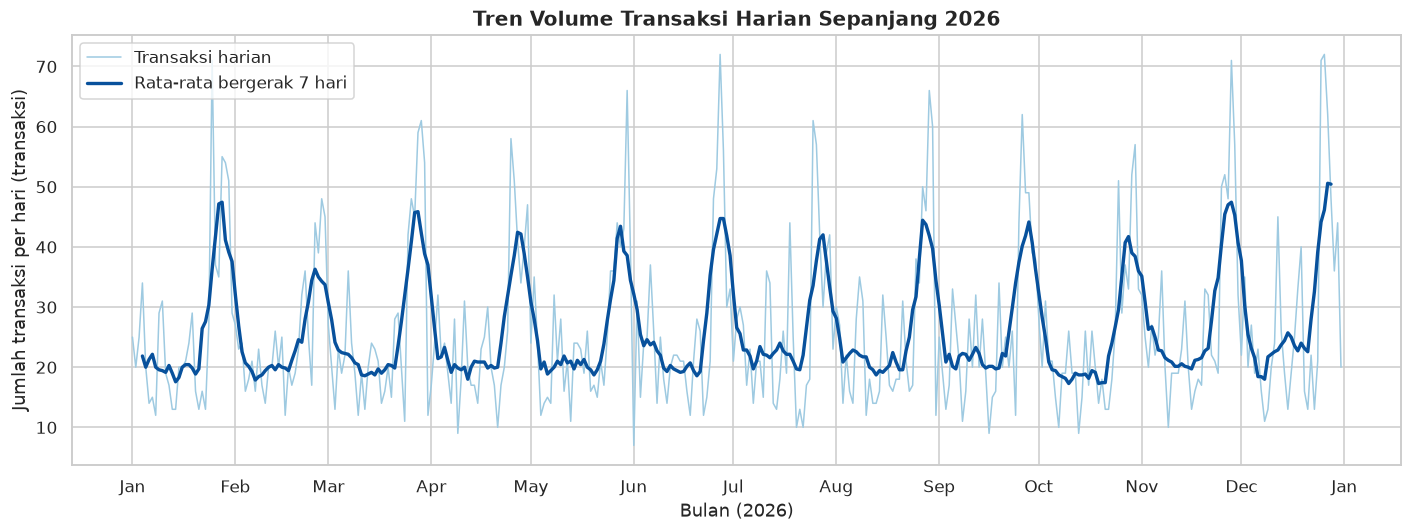

In [26]:
harian = df.groupby("Purchase_Date").size().rename("Transaksi").reset_index()
harian["MA7"] = harian["Transaksi"].rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(harian["Purchase_Date"], harian["Transaksi"], color="#9ecae1", linewidth=1, label="Transaksi harian")
ax.plot(harian["Purchase_Date"], harian["MA7"], color="#08519c", linewidth=2.2, label="Rata-rata bergerak 7 hari")
ax.set_title("Tren Volume Transaksi Harian Sepanjang 2026", fontsize=13, fontweight="bold")
ax.set_xlabel("Bulan (2026)")
ax.set_ylabel("Jumlah transaksi per hari (transaksi)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend()
plt.tight_layout()
plt.savefig("charts/H1_tren_harian.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 1.1 (Tren harian).** Volume transaksi harian membentuk siklus yang berulang setiap bulan: rata-rata 7 hari naik tajam menjelang akhir bulan (puncak bulanan sekitar 36 sampai 51 transaksi per hari), lalu turun ke kisaran 17-20 transaksi per hari. Rata-rata harian sepanjang 2026 sekitar 26 transaksi, dan puncak tertinggi terjadi pada akhir Desember. Pola yang berulang ini penting secara bisnis karena kebutuhan stok, kurir, dan layanan pelanggan sangat tidak merata sepanjang bulan.

### Grafik 1.2 | Rata-rata Transaksi per Hari Berdasarkan Tanggal dalam Bulan

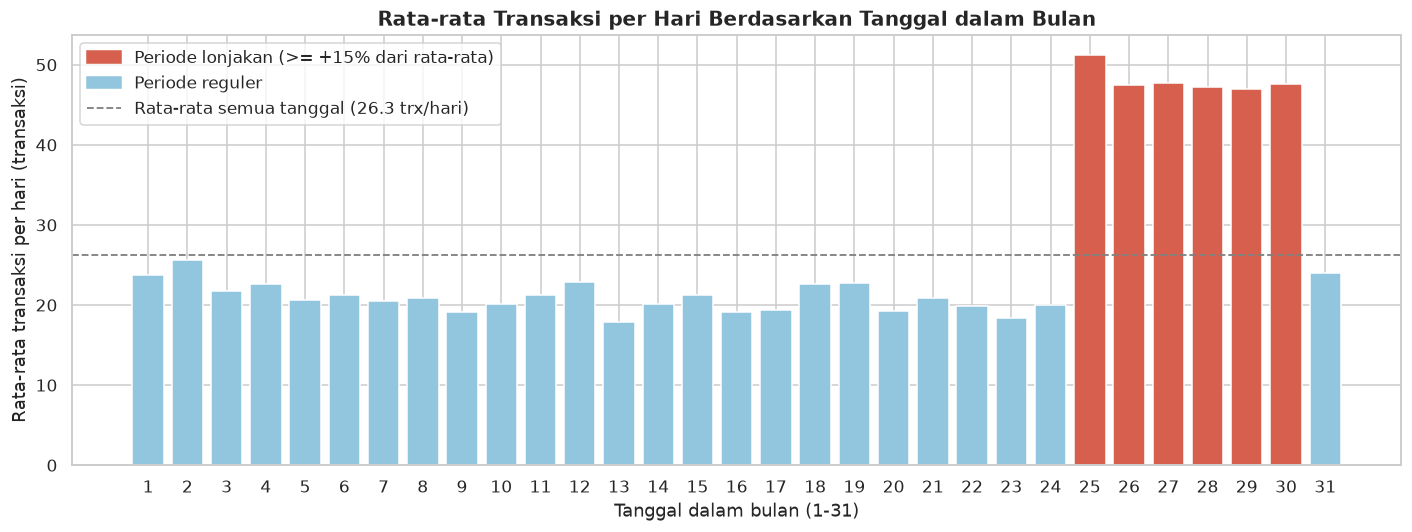

In [27]:
per_tanggal = harian.groupby(harian["Purchase_Date"].dt.day)["Transaksi"].mean()
batas = per_tanggal.mean() * 1.15
warna = ["#d6604d" if v >= batas else "#92c5de" for v in per_tanggal.values]

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(per_tanggal.index, per_tanggal.values, color=warna)
ax.axhline(per_tanggal.mean(), color="gray", linestyle="--", linewidth=1.2)
ax.set_title("Rata-rata Transaksi per Hari Berdasarkan Tanggal dalam Bulan", fontsize=13, fontweight="bold")
ax.set_xlabel("Tanggal dalam bulan (1-31)")
ax.set_ylabel("Rata-rata transaksi per hari (transaksi)")
ax.set_xticks(range(1, 32))
ax.legend(handles=[
    Patch(color="#d6604d", label="Periode lonjakan (>= +15% dari rata-rata)"),
    Patch(color="#92c5de", label="Periode reguler"),
    Line2D([0], [0], color="gray", linestyle="--", linewidth=1.2,
           label=f"Rata-rata semua tanggal ({per_tanggal.mean():.1f} trx/hari)")
], loc="upper left")
plt.tight_layout()
plt.savefig("charts/H1_tanggal_dalam_bulan.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 1.2 (Tanggal dalam bulan).** Tanggal 25-30 rata-rata mencatat 47-51 transaksi per hari, lebih dari dua kali lipat dibanding tanggal lain yang hanya sekitar 18-26 transaksi, dan tanggal 31 kembali turun ke sekitar 24. Lonjakan ini muncul di seluruh 12 bulan dan diduga terkait waktu gajian, tetapi data tidak dapat membuktikan penyebabnya. Secara bisnis, promo, stok, dan kapasitas layanan perlu difokuskan pada tanggal 25-30 setiap bulan.

### Grafik 1.3 | Heatmap Jumlah Transaksi: Hari × Jam

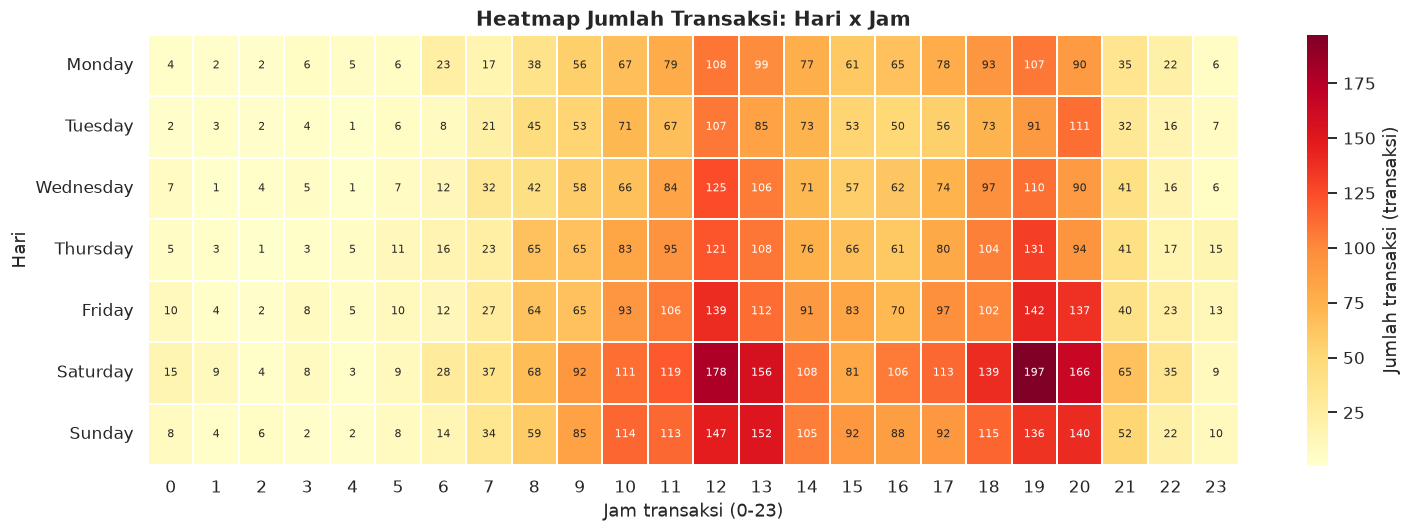

In [28]:
urutan_hari = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot = (df.pivot_table(index="Purchase_Day", columns="Purchase_Hour",
                        values="Transaction_ID", aggfunc="count", fill_value=0)
           .reindex(urutan_hari).reindex(columns=range(24), fill_value=0))

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt="d", annot_kws={"size": 7}, linewidths=0.3,
            cbar_kws={"label": "Jumlah transaksi (transaksi)"}, ax=ax)
ax.set_title("Heatmap Jumlah Transaksi: Hari x Jam", fontsize=13, fontweight="bold")
ax.set_xlabel("Jam transaksi (0-23)")
ax.set_ylabel("Hari")
plt.tight_layout()
plt.savefig("charts/H1_heatmap_hari_jam.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 1.3 (Heatmap hari x jam).** Sabtu adalah hari tersibuk (1.856 transaksi), disusul Minggu (1.600) dan Jumat (1.455), sedangkan Selasa paling sepi (1.037). Puncak jam terjadi pada pukul 12.00 (925 transaksi) dan 19.00 (914), dengan sel tersibuk Sabtu pukul 19.00 (197 transaksi). Pukul 01.00-04.00 sangat sepi (total 105 transaksi), meskipun sebagian dipengaruhi pembersihan data yang mengeluarkan transaksi gerai fisik pada jam 00-07 dan 23. Promo kilat dan penjadwalan staf sebaiknya mengikuti pola akhir pekan serta jam makan siang dan malam.

## C.2 Kontribusi Geografis
> **Pertanyaan brief:** Wilayah (`Region`) mana yang menyumbang volume dan nilai transaksi tertinggi, dan bagaimana kontribusi masing-masing kota (`City`) di dalam wilayah tersebut?

In [29]:
region = (df.groupby("Region")
            .agg(Transaksi=("Transaction_ID", "count"), Nilai=("Purchase_Amount", "sum"))
            .sort_values("Nilai", ascending=False))
region["Nilai_M"] = region["Nilai"] / 1e9
region["Pct_Trx"] = region["Transaksi"] / region["Transaksi"].sum() * 100
region["Pct_Nilai"] = region["Nilai"] / region["Nilai"].sum() * 100

urut_region = region.index.tolist()
warna_region = dict(zip(urut_region, sns.color_palette("colorblind", len(urut_region))))

region.round(2)

,Transaksi,Nilai,Nilai_M,Pct_Trx,Pct_Nilai
Region,,,,,
Jabodetabek,3932,6893969150,6.89,41.14,36.19
West Java,1650,3381092550,3.38,17.26,17.75
East Java,1518,3349590850,3.35,15.88,17.58
Central Java,1467,3102443050,3.10,15.35,16.29
Sumatera,990,2322451000,2.32,10.36,12.19


### Grafik 2.1 | Kontribusi Wilayah terhadap Volume dan Nilai Transaksi 2026

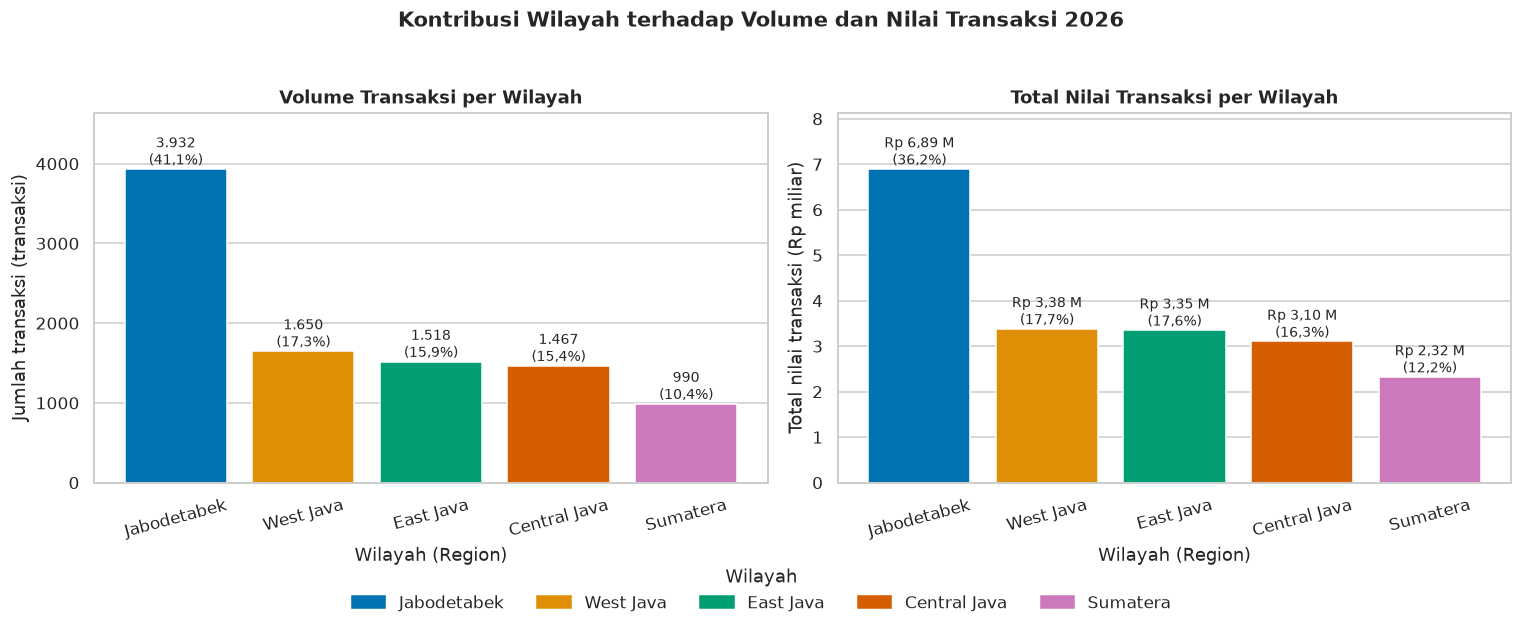

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].bar(urut_region, region["Transaksi"], color=[warna_region[r] for r in urut_region])
for i, r in enumerate(urut_region):
    axes[0].text(i, region.loc[r, "Transaksi"],
                 f"{fmt_id(region.loc[r, 'Transaksi'])}\n({fmt_id(region.loc[r, 'Pct_Trx'], 1)}%)",
                 ha="center", va="bottom", fontsize=9)
axes[0].set_title("Volume Transaksi per Wilayah", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Wilayah (Region)")
axes[0].set_ylabel("Jumlah transaksi (transaksi)")
axes[0].set_ylim(0, region["Transaksi"].max() * 1.18)

axes[1].bar(urut_region, region["Nilai_M"], color=[warna_region[r] for r in urut_region])
for i, r in enumerate(urut_region):
    axes[1].text(i, region.loc[r, "Nilai_M"],
                 f"Rp {fmt_id(region.loc[r, 'Nilai_M'], 2)} M\n({fmt_id(region.loc[r, 'Pct_Nilai'], 1)}%)",
                 ha="center", va="bottom", fontsize=9)
axes[1].set_title("Total Nilai Transaksi per Wilayah", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Wilayah (Region)")
axes[1].set_ylabel("Total nilai transaksi (Rp miliar)")
axes[1].set_ylim(0, region["Nilai_M"].max() * 1.18)

for ax in axes:
    ax.tick_params(axis="x", rotation=15)
    ax.grid(False, axis="x")

fig.legend(handles=[Patch(color=warna_region[r], label=r) for r in urut_region],
           title="Wilayah", loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.04), frameon=False)
fig.suptitle("Kontribusi Wilayah terhadap Volume dan Nilai Transaksi 2026", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("charts/H2_region_volume_nilai.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 2.1 (Wilayah).** Jabodetabek tertinggi pada volume (3.932 transaksi, 41,1%) maupun nilai (Rp 6,89 miliar, 36,2% dari total Rp 19,05 miliar). West Java, East Java, dan Central Java nilainya berdekatan (16,3%-17,7%), sedangkan Sumatera terendah (990 transaksi, Rp 2,32 miliar). Porsi nilai Jabodetabek lebih kecil daripada porsi volumenya, artinya nilai per transaksi di sana relatif lebih rendah. Perlu dicatat bahwa Jabodetabek memiliki lima kota sedangkan wilayah lain tiga, sehingga sebagian selisih total berasal dari jumlah kota. Sebagaimana ditunjukkan pada **Bagian B.3**, total nilai Rp 19,05 miliar tersebut masih mencakup Rp 8,74 miliar (**45,9%**) dari **148 transaksi mencurigakan**, sehingga stabilitas kontribusi antarwilayah tanpa baris mencurigakan diuji secara eksplisit setelah Tabel 3.3.

### Grafik 2.2 | Kontribusi Kota terhadap Total Nilai Transaksi di Tiap Wilayah

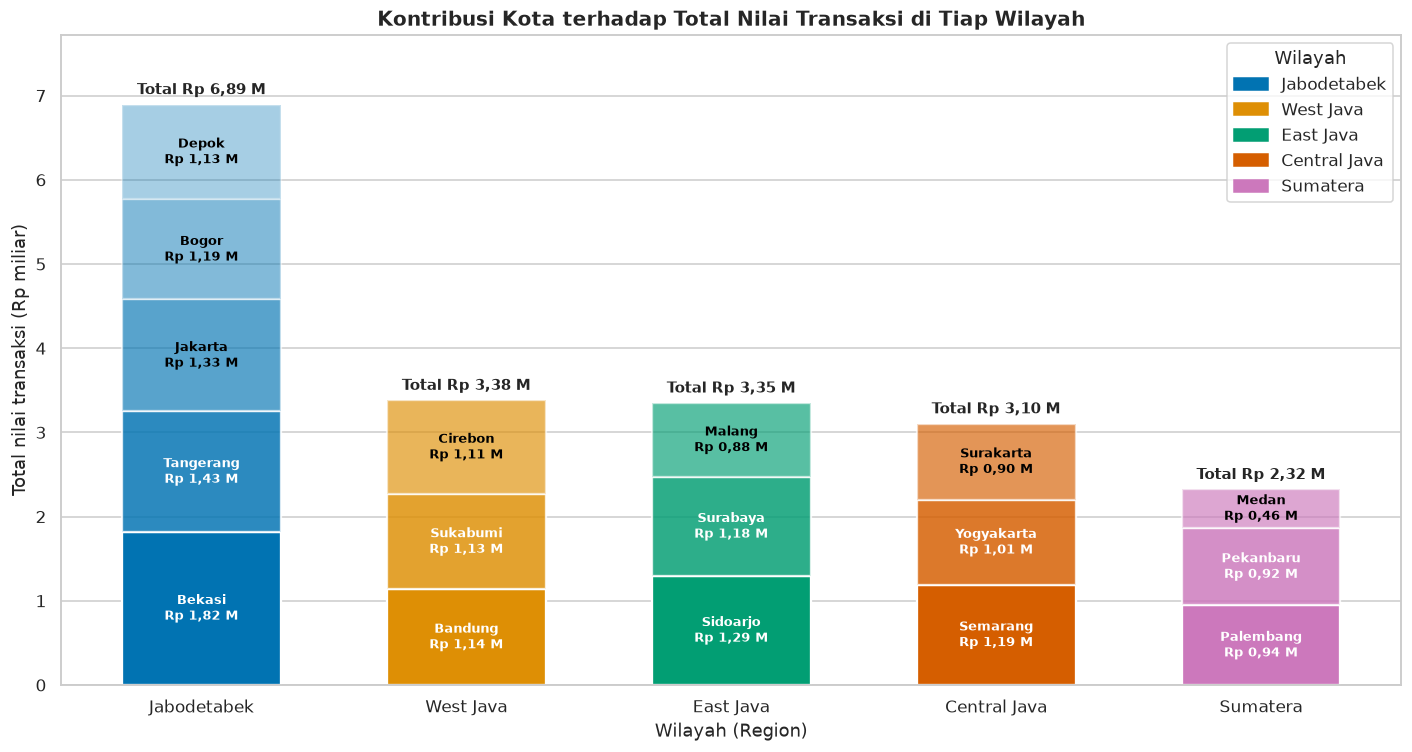

In [31]:
kota = (df.groupby(["Region", "City"])["Purchase_Amount"].sum().div(1e9)
          .rename("Nilai_M").reset_index())

fig, ax = plt.subplots(figsize=(13, 7))
for i, r in enumerate(urut_region):
    sub = kota[kota["Region"] == r].sort_values("Nilai_M", ascending=False)
    bawah = 0
    for j, (_, baris) in enumerate(sub.iterrows()):
        alpha = max(1.0 - j * 0.17, 0.35)
        ax.bar(i, baris["Nilai_M"], bottom=bawah, color=warna_region[r], alpha=alpha,
               edgecolor="white", linewidth=1.5, width=0.6)
        ax.text(i, bawah + baris["Nilai_M"] / 2,
                f"{baris['City']}\nRp {fmt_id(baris['Nilai_M'], 2)} M",
                ha="center", va="center", fontsize=8.5,
                color="black" if alpha < 0.7 else "white", fontweight="bold")
        bawah += baris["Nilai_M"]
    ax.text(i, bawah + 0.08, f"Total Rp {fmt_id(bawah, 2)} M",
            ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_xticks(range(len(urut_region)))
ax.set_xticklabels(urut_region)
ax.set_xlabel("Wilayah (Region)")
ax.set_ylabel("Total nilai transaksi (Rp miliar)")
ax.set_title("Kontribusi Kota terhadap Total Nilai Transaksi di Tiap Wilayah", fontsize=13, fontweight="bold")
ax.set_ylim(0, region["Nilai_M"].max() * 1.12)
ax.grid(False, axis="x")
ax.legend(handles=[Patch(color=warna_region[r], label=r) for r in urut_region], title="Wilayah", loc="upper right")
plt.tight_layout()
plt.savefig("charts/H2_kota_per_region.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 2.2 (Kota di dalam wilayah).** Di Jabodetabek, Bekasi menyumbang nilai terbesar (Rp 1,82 miliar, 26,4% dari nilai wilayah), disusul Tangerang (20,7%), Jakarta (19,3%), Bogor (17,3%), dan Depok (16,3%). Depok memiliki transaksi terbanyak (917) namun nilainya terkecil di antara lima kota tersebut, sehingga banyaknya transaksi tidak otomatis berarti besarnya nilai. Di luar Jabodetabek, tiap kota menyumbang 26-41% nilai wilayahnya (West Java hampir merata, sekitar sepertiga per kota), kecuali Medan yang hanya 19,6% dan merupakan kota dengan nilai terkecil dari seluruh kota (Rp 0,46 miliar). Strategi perlu dibedakan per kota: meningkatkan nilai per transaksi di Depok dan memperluas jangkauan di Medan.

### Tabel 2.3 | Ringkasan Kontribusi Kota per Wilayah

In [32]:
tabel = (df.groupby(["Region", "City"])
           .agg(Transaksi=("Transaction_ID", "count"), Nilai=("Purchase_Amount", "sum"))
           .reset_index())
tabel["Pct_trx_dlm_wilayah"] = (tabel["Transaksi"] / tabel.groupby("Region")["Transaksi"].transform("sum") * 100).round(1)
tabel["Pct_nilai_dlm_wilayah"] = (tabel["Nilai"] / tabel.groupby("Region")["Nilai"].transform("sum") * 100).round(1)
tabel["Nilai_Rp_miliar"] = (tabel["Nilai"] / 1e9).round(2)
tabel = tabel.drop(columns="Nilai").sort_values(["Region", "Nilai_Rp_miliar"], ascending=[True, False])
tabel

,Region,City,Transaksi,Pct_trx_dlm_wilayah,Pct_nilai_dlm_wilayah,Nilai_Rp_miliar
0,Central Java,Semarang,550,37.50,38.30,1.19
2,Central Java,Yogyakarta,496,33.80,32.60,1.01
1,Central Java,Surakarta,421,28.70,29.10,0.90
4,East Java,Sidoarjo,504,33.20,38.70,1.29
5,East Java,Surabaya,501,33.00,35.10,1.18
3,East Java,Malang,513,33.80,26.20,0.88
6,Jabodetabek,Bekasi,757,19.30,26.40,1.82
10,Jabodetabek,Tangerang,730,18.60,20.70,1.43
9,Jabodetabek,Jakarta,759,19.30,19.30,1.33
7,Jabodetabek,Bogor,769,19.60,17.30,1.19


*Tabel di atas melengkapi Grafik 2.2: jumlah transaksi, kontribusi transaksi dan nilai tiap kota di dalam wilayahnya, serta nilai dalam Rp miliar.*

## C.3 Pengaruh Membership dan Kategori Produk
> **Pertanyaan brief:** Apakah pelanggan dengan tingkat `Membership_Level` lebih tinggi membelanjakan uang lebih banyak dibanding tier di bawahnya? Kategori produk (`Product_Category`) mana yang memiliki nilai transaksi terbesar? (Grafik harus mampu memperlihatkan sebaran data, bukan sekadar rata-rata.)

In [33]:
urut_member = ["Basic", "Silver", "Gold", "Premium"]
warna_member = dict(zip(urut_member, sns.color_palette("YlGnBu", 6)[1:5]))

mean_props = dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=6)
flier_props = dict(marker="o", markersize=2.5, alpha=0.35, markerfacecolor="gray", markeredgecolor="none")
legenda_box = [
    Line2D([0], [0], color="black", linewidth=2, label="Median (garis tengah kotak)"),
    Line2D([0], [0], marker="D", color="w", markerfacecolor="white", markeredgecolor="black", markersize=7, label="Rata-rata"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="gray", alpha=0.6, markersize=5,
           label="Outlier IQR per kelompok (berbeda dari outlier global B.3)"),
]

### Grafik 3.1 | Sebaran Nilai Transaksi Berdasarkan Level Membership

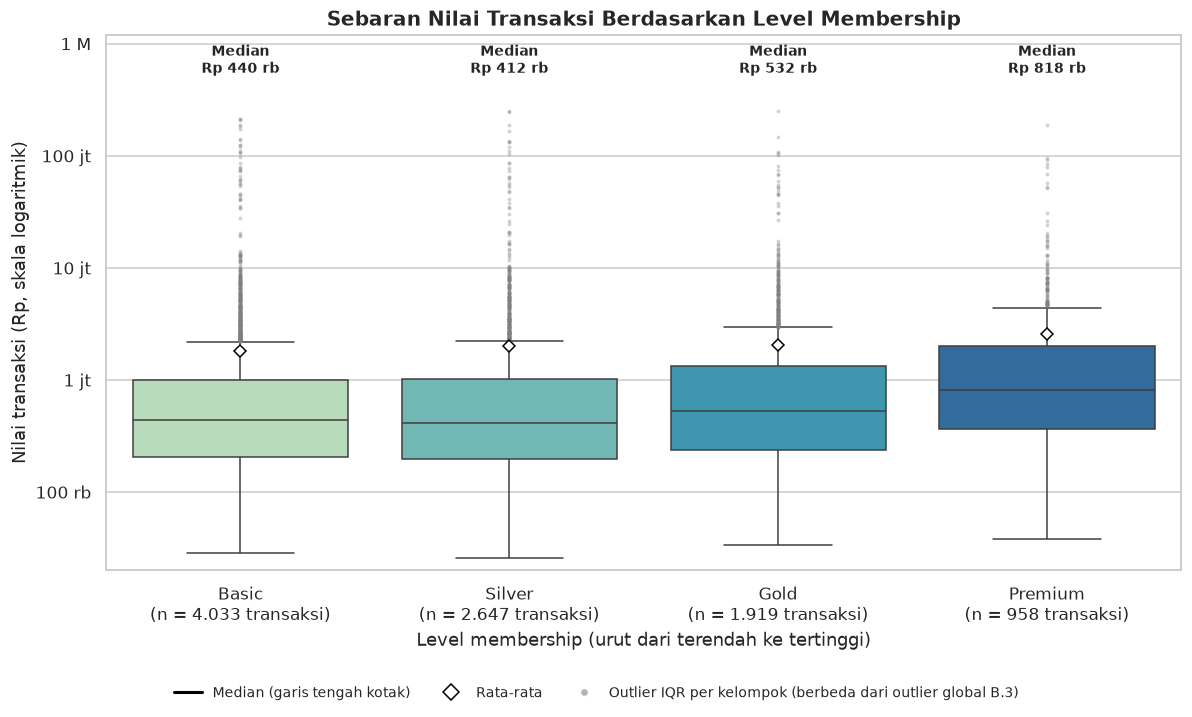

In [34]:
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.boxplot(data=df, x="Membership_Level", y="Purchase_Amount", order=urut_member,
            hue="Membership_Level", hue_order=urut_member, palette=warna_member, legend=False,
            showmeans=True, meanprops=mean_props, flierprops=flier_props, ax=ax)
ax.set_yscale("log")
ax.set_ylim(2e4, 1.2e9)
ax.yaxis.set_major_formatter(FuncFormatter(rp_singkat))

n_per = df["Membership_Level"].value_counts()
med_per = df.groupby("Membership_Level")["Purchase_Amount"].median()
ax.set_xticks(range(4))
ax.set_xticklabels([f"{m}\n(n = {fmt_id(n_per[m])} transaksi)" for m in urut_member])
for i, m in enumerate(urut_member):
    ax.text(i, 5e8, f"Median\nRp {fmt_id(med_per[m] / 1e3)} rb", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_title("Sebaran Nilai Transaksi Berdasarkan Level Membership", fontsize=13, fontweight="bold")
ax.set_xlabel("Level membership (urut dari terendah ke tertinggi)")
ax.set_ylabel("Nilai transaksi (Rp, skala logaritmik)")
fig.legend(handles=legenda_box, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01), frameon=False, fontsize=9)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig("charts/H3_boxplot_membership.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 3.1 (Membership).** Median nilai transaksi Basic Rp 440 ribu, Silver Rp 412 ribu, Gold Rp 532 ribu, dan Premium Rp 818 ribu. Jadi hipotesis manajemen hanya sebagian benar: Gold dan Premium belanja lebih besar dari tier di bawahnya, tetapi Silver tidak lebih tinggi dari Basic. Sebaran tiap tier juga banyak tumpang tindih (bagian atas kotak Basic, sekitar Rp 1 juta, sudah di atas median Premium), sehingga level membership saja belum cukup menjelaskan besar belanja. Rata-rata (◆) berada jauh di atas median pada semua tier karena pengaruh outlier, sehingga median lebih tepat untuk mewakili belanja tipikal. Sumbu Y memakai skala logaritmik. Temuan ini sekaligus selaras dengan **Bagian B.3.1**: proporsi outlier naik seiring tier (Premium tertinggi 19,6%), tetapi belanja tipikal (median) baru meningkat pada Gold dan Premium, bukan pada Silver.

### Grafik 3.2 | Nilai Transaksi Berdasarkan Kategori Produk

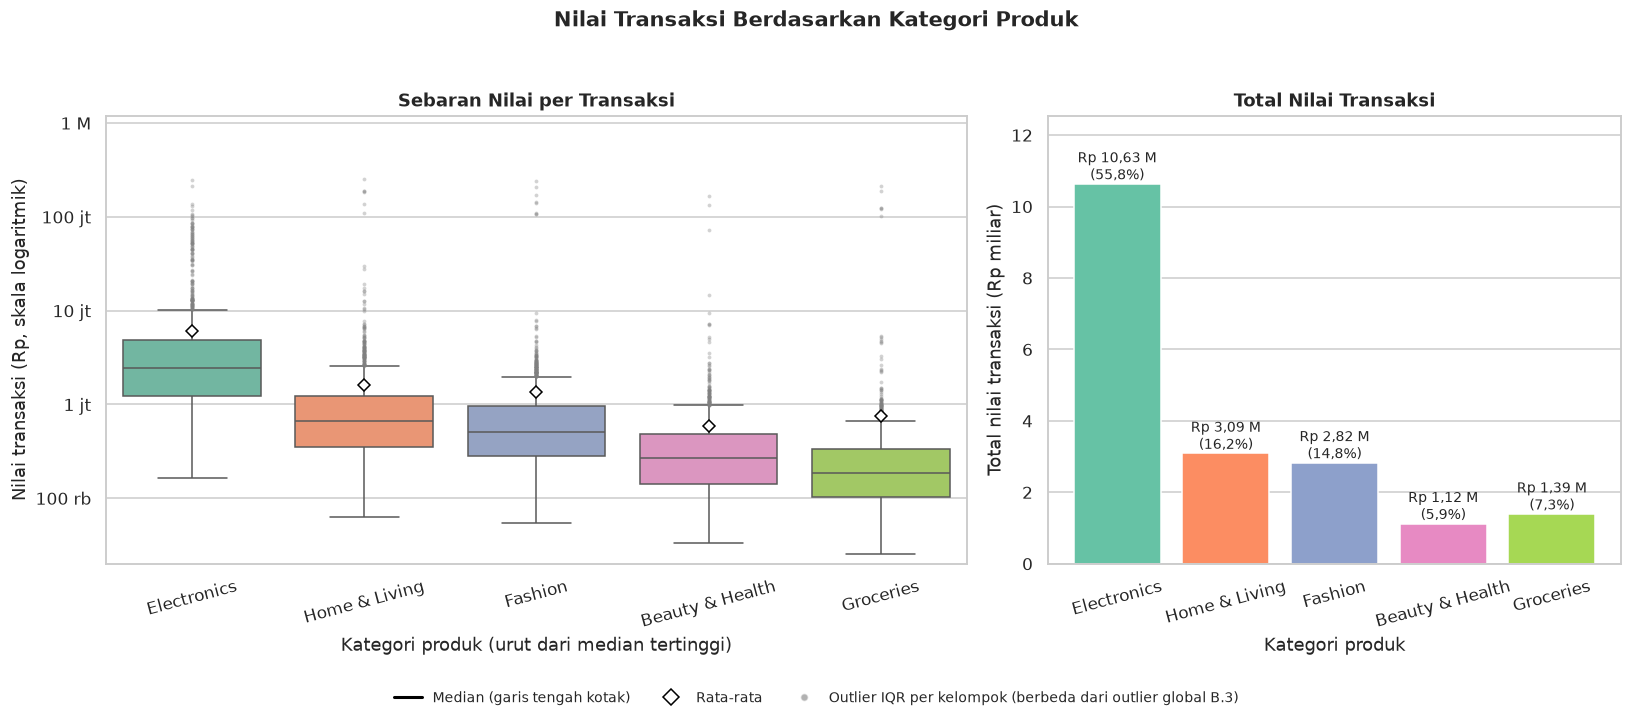

In [35]:
urut_kat = df.groupby("Product_Category")["Purchase_Amount"].median().sort_values(ascending=False).index.tolist()
warna_kat = dict(zip(urut_kat, sns.color_palette("Set2", len(urut_kat))))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})

sns.boxplot(data=df, x="Product_Category", y="Purchase_Amount", order=urut_kat,
            hue="Product_Category", hue_order=urut_kat, palette=warna_kat, legend=False,
            showmeans=True, meanprops=mean_props, flierprops=flier_props, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_ylim(2e4, 1.2e9)
axes[0].yaxis.set_major_formatter(FuncFormatter(rp_singkat))
axes[0].set_title("Sebaran Nilai per Transaksi", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Kategori produk (urut dari median tertinggi)")
axes[0].set_ylabel("Nilai transaksi (Rp, skala logaritmik)")
axes[0].tick_params(axis="x", rotation=15)

total = (df.groupby("Product_Category")["Purchase_Amount"].sum() / 1e9).reindex(urut_kat)
pct = total / total.sum() * 100
axes[1].bar(urut_kat, total.values, color=[warna_kat[k] for k in urut_kat])
for i, k in enumerate(urut_kat):
    axes[1].text(i, total[k], f"Rp {fmt_id(total[k], 2)} M\n({fmt_id(pct[k], 1)}%)", ha="center", va="bottom", fontsize=9)
axes[1].set_ylim(0, total.max() * 1.18)
axes[1].set_title("Total Nilai Transaksi", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Kategori produk")
axes[1].set_ylabel("Total nilai transaksi (Rp miliar)")
axes[1].tick_params(axis="x", rotation=15)
axes[1].grid(False, axis="x")

fig.suptitle("Nilai Transaksi Berdasarkan Kategori Produk", fontsize=14, fontweight="bold")
fig.legend(handles=legenda_box, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01), frameon=False, fontsize=9)
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.savefig("charts/H3_boxplot_kategori.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 3.2 (Kategori produk).** Electronics memiliki nilai per transaksi tertinggi (median sekitar Rp 2,46 juta, lihat Tabel 3.3 di bawah) dan kontribusi total terbesar, yaitu Rp 10,63 miliar atau 55,8% dari seluruh nilai transaksi. Kategori lain jauh di bawahnya: Home & Living 16,2%, Fashion 14,8%, Groceries 7,3%, dan Beauty & Health 5,9%. Pada Groceries, rata-rata (◆) jauh di atas median, menandakan adanya beberapa transaksi pembelian besar. Dari sisi bisnis, performa omzet sangat bergantung pada kategori Electronics. Secara khusus, rata-rata (◆) pada Groceries tampak jauh di atas median karena tertarik oleh **19 transaksi mencurigakan** dari B.3; tanpa transaksi tersebut, rata-rata Groceries turun dari sekitar Rp 743 ribu menjadi **Rp 254 ribu**.

### Tabel 3.3 | Median Nilai Transaksi per Kategori Produk

In [36]:
df.groupby("Product_Category")["Purchase_Amount"].median().sort_values(ascending=False)

Product_Category
Electronics       2,459,850.00
Home & Living       660,400.00
Fashion             513,000.00
Beauty & Health     265,600.00
Groceries           184,750.00
Name: Purchase_Amount, dtype: float64

### Uji Ketahanan Temuan C terhadap 148 Transaksi Mencurigakan (B.3)

In [37]:
df_tanpa = df[~df['mencurigakan']].copy()

print('=== 1. Porsi Nilai Kategori Electronics ===')
for label, d in [('Data Bersih (n=9.557)', df), ('Tanpa 148 Mencurigakan (n=9.409)', df_tanpa)]:
    tot_n = d['Purchase_Amount'].sum()
    el_n = d.loc[d['Product_Category'] == 'Electronics', 'Purchase_Amount'].sum()
    print(f'{label:34s}: Total Rp {tot_n/1e9:.2f} M | Electronics Rp {el_n/1e9:.2f} M ({el_n/tot_n*100:.1f}%)')

print('\n=== 2. Porsi Volume & Nilai per Region ===')
reg_uji = pd.DataFrame({
    'Vol_%_Bersih': df['Region'].value_counts(normalize=True) * 100,
    'Nilai_%_Bersih': df.groupby('Region')['Purchase_Amount'].sum() / df['Purchase_Amount'].sum() * 100,
    'Vol_%_Tanpa148': df_tanpa['Region'].value_counts(normalize=True) * 100,
    'Nilai_%_Tanpa148': df_tanpa.groupby('Region')['Purchase_Amount'].sum() / df_tanpa['Purchase_Amount'].sum() * 100,
}).loc[urut_region].round(1)
display(reg_uji)

print('=== 3. Median Nilai Transaksi per Membership_Level ===')
mem_uji = pd.DataFrame({
    'Median_Bersih': df.groupby('Membership_Level')['Purchase_Amount'].median(),
    'Median_Tanpa148': df_tanpa.groupby('Membership_Level')['Purchase_Amount'].median(),
}).reindex(urut_member)
display(mem_uji)

print('=== 4. Mean vs. Median Kategori Groceries ===')
g_all = df[df['Product_Category'] == 'Groceries']['Purchase_Amount']
g_clean = df_tanpa[df_tanpa['Product_Category'] == 'Groceries']['Purchase_Amount']
print(f"Groceries Bersih (n={len(g_all)}, termasuk {int(df.loc[df['Product_Category']=='Groceries', 'mencurigakan'].sum())} mencurigakan): Mean Rp {g_all.mean():,.0f} | Median Rp {g_all.median():,.0f}")
print(f"Groceries Tanpa 148 Mencurigakan (n={len(g_clean)})              : Mean Rp {g_clean.mean():,.0f} | Median Rp {g_clean.median():,.0f}")

=== 1. Porsi Nilai Kategori Electronics ===
Data Bersih (n=9.557)             : Total Rp 19.05 M | Electronics Rp 10.63 M (55.8%)
Tanpa 148 Mencurigakan (n=9.409)  : Total Rp 10.31 M | Electronics Rp 5.84 M (56.6%)

=== 2. Porsi Volume & Nilai per Region ===


,Vol_%_Bersih,Nilai_%_Bersih,Vol_%_Tanpa148,Nilai_%_Tanpa148
Region,,,,
Jabodetabek,41.10,36.20,41.20,39.40
West Java,17.30,17.70,17.30,17.20
East Java,15.90,17.60,15.90,17.10
Central Java,15.40,16.30,15.30,15.80
Sumatera,10.40,12.20,10.30,10.50


=== 3. Median Nilai Transaksi per Membership_Level ===


,Median_Bersih,Median_Tanpa148
Membership_Level,,
Basic,"440,300.00","432,000.00"
Silver,"412,500.00","397,100.00"
Gold,"532,000.00","519,650.00"
Premium,"817,950.00","796,800.00"


=== 4. Mean vs. Median Kategori Groceries ===
Groceries Bersih (n=1868, termasuk 19 mencurigakan): Mean Rp 743,120 | Median Rp 184,750
Groceries Tanpa 148 Mencurigakan (n=1849)              : Mean Rp 254,363 | Median Rp 182,750


**Insight Uji Ketahanan (C.3):** Menyisihkan 148 baris mencurigakan dari B.3 ($n = 9.409$) tidak mengubah satu pun kesimpulan kualitatif pada Bagian C: Electronics tetap mendominasi total nilai (**56,6%** vs. 55,8%), porsi nilai Jabodetabek (**39,4%**) tetap lebih rendah daripada porsi volumenya (**41,2%**; pada data bersih 41,1%), dan median Silver (**Rp 397.100**) tetap di bawah Basic (**Rp 432.000**). Perubahan besar hanya terjadi pada total nilai nominal dan metrik rata-rata kategori berekor panjang (mis. mean Groceries turun dari Rp 743 ribu menjadi **Rp 254 ribu**), yang memvalidasi pilihan median sebagai KPI utama di Bagian C.

## C.4 Korelasi Kepuasan Pelanggan
> **Pertanyaan brief:** Apakah pelanggan dengan skor `Customer_Satisfaction` tinggi (4 dan 5) cenderung melakukan pembelian dengan nilai `Purchase_Amount` yang lebih besar dibandingkan pelanggan yang kurang puas (skor 1 dan 2)?

In [38]:
df["log_amount"] = np.log10(df["Purchase_Amount"])
df["Kelompok_Puas"] = pd.cut(df["Customer_Satisfaction"], bins=[0, 2, 3, 5],
                             labels=["Kurang puas (1-2)", "Netral (3)", "Puas (4-5)"])

# Spearman = korelasi Pearson pada peringkat (tidak butuh scipy)
rho = df["Customer_Satisfaction"].rank().corr(df["Purchase_Amount"].rank())
skor = [1, 2, 3, 4, 5]
warna_skor = dict(zip(skor, sns.color_palette("RdYlBu", 5)))
n_skor = df["Customer_Satisfaction"].value_counts()
med_skor = df.groupby("Customer_Satisfaction")["Purchase_Amount"].median()

print("Korelasi Spearman:", round(rho, 4))

Korelasi Spearman: 0.0929


### Grafik 4.1 | Sebaran Nilai Transaksi menurut Skor Kepuasan Pelanggan

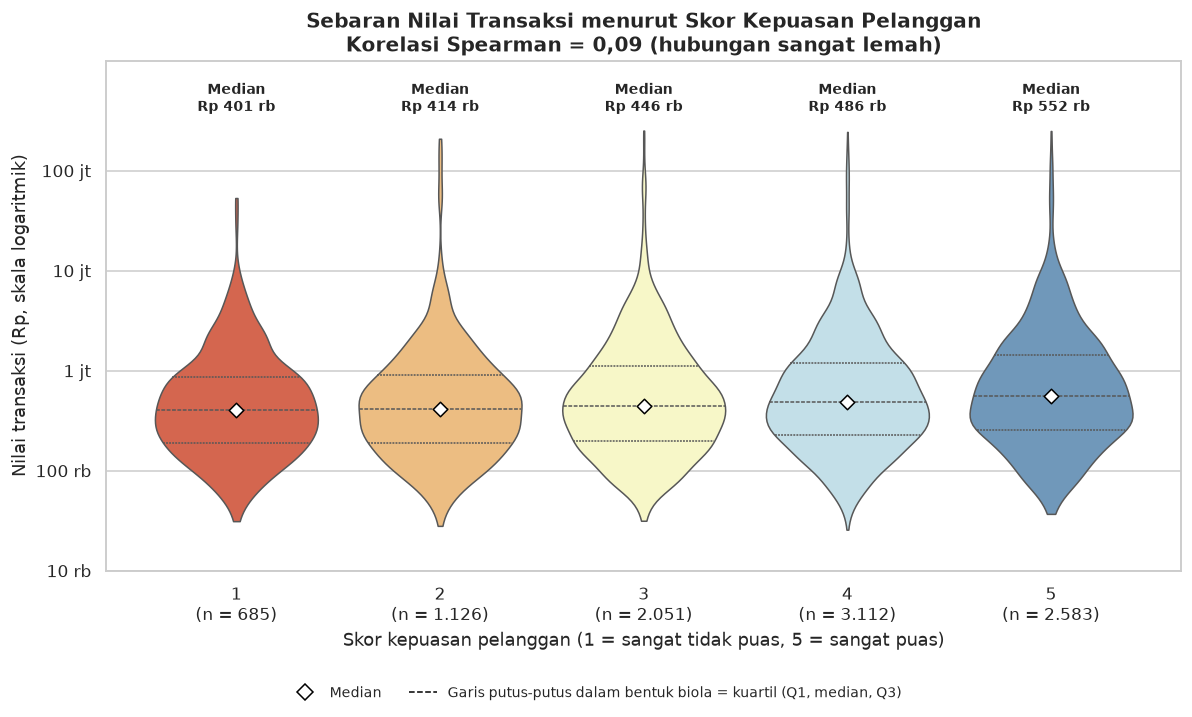

In [39]:
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.violinplot(data=df, x="Customer_Satisfaction", y="log_amount", order=skor,
               hue="Customer_Satisfaction", hue_order=skor, palette=warna_skor, legend=False,
               inner="quart", cut=0, linewidth=1, ax=ax)
ax.scatter(range(5), np.log10(med_skor.reindex(skor).values), marker="D", s=45,
           color="white", edgecolor="black", zorder=5)
for i, s in enumerate(skor):
    ax.text(i, 8.55, f"Median\n{rp_pendek(med_skor[s])}", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_ylim(4.2, 9.1)
ax.set_yticks([4, 5, 6, 7, 8])
ax.set_yticklabels(["10 rb", "100 rb", "1 jt", "10 jt", "100 jt"])
ax.set_xticks(range(5))
ax.set_xticklabels([f"{s}\n(n = {fmt_id(n_skor[s])})" for s in skor])
ax.set_xlabel("Skor kepuasan pelanggan (1 = sangat tidak puas, 5 = sangat puas)")
ax.set_ylabel("Nilai transaksi (Rp, skala logaritmik)")
ax.set_title(f"Sebaran Nilai Transaksi menurut Skor Kepuasan Pelanggan\nKorelasi Spearman = {fmt_id(rho, 2)} (hubungan sangat lemah)",
             fontsize=13, fontweight="bold")
legenda = [Line2D([0], [0], marker="D", color="w", markerfacecolor="white", markeredgecolor="black", markersize=7, label="Median"),
           Line2D([0], [0], color="black", linestyle="--", linewidth=1, label="Garis putus-putus dalam bentuk biola = kuartil (Q1, median, Q3)")]
fig.legend(handles=legenda, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.01), frameon=False, fontsize=9)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig("charts/H4_violin_kepuasan.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 4.1 (Sebaran per skor).** Median nilai transaksi naik seiring skor kepuasan: Rp 401 ribu (skor 1), Rp 414 ribu, Rp 446 ribu, Rp 486 ribu, hingga Rp 552 ribu (skor 5). Kelompok puas (skor 4-5) bermedian Rp 512 ribu, sekitar 25% lebih tinggi daripada kelompok kurang puas (skor 1-2) yang Rp 411 ribu (lihat sel verifikasi di akhir notebook). Namun hubungannya sangat lemah (korelasi Spearman 0,09) dan sebaran semua skor saling tumpang tindih besar, sehingga skor kepuasan bukan penentu utama besar belanja. Spearman dipilih karena skor kepuasan bersifat ordinal dan nilai belanja sangat miring.

### Grafik 4.2 | Selisih Median Nilai Transaksi: Pelanggan Puas (4-5) vs Kurang Puas (1-2), per Kategori Produk

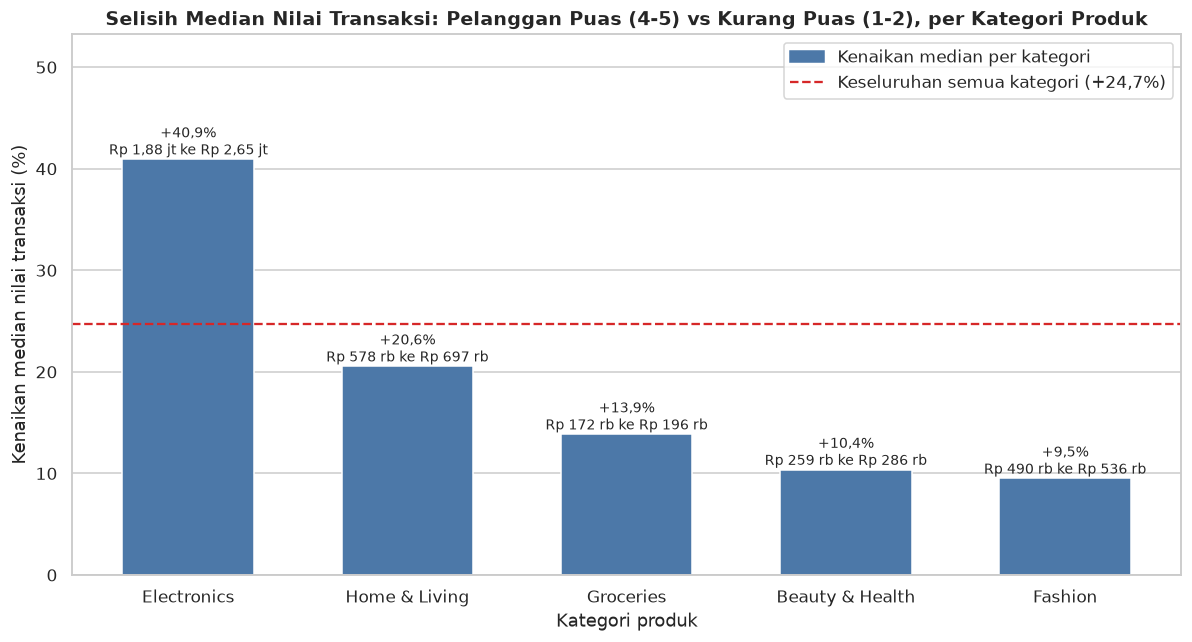

In [40]:
med = df.pivot_table(index="Product_Category", columns="Kelompok_Puas", values="Purchase_Amount",
                     aggfunc="median", observed=True)
uplift = ((med["Puas (4-5)"] / med["Kurang puas (1-2)"] - 1) * 100).sort_values(ascending=False)
overall = (df.loc[df["Customer_Satisfaction"] >= 4, "Purchase_Amount"].median() /
           df.loc[df["Customer_Satisfaction"] <= 2, "Purchase_Amount"].median() - 1) * 100

fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(uplift.index, uplift.values, color="#4c78a8", width=0.6)
for i, k in enumerate(uplift.index):
    ax.text(i, uplift[k], f"+{fmt_id(uplift[k], 1)}%\n{rp_pendek(med.loc[k, 'Kurang puas (1-2)'])} ke {rp_pendek(med.loc[k, 'Puas (4-5)'])}",
            ha="center", va="bottom", fontsize=9)
ax.axhline(overall, color="#d62728", linestyle="--", linewidth=1.5)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylim(0, uplift.max() * 1.3)
ax.set_title("Selisih Median Nilai Transaksi: Pelanggan Puas (4-5) vs Kurang Puas (1-2), per Kategori Produk",
             fontsize=12.5, fontweight="bold")
ax.set_xlabel("Kategori produk")
ax.set_ylabel("Kenaikan median nilai transaksi (%)")
ax.grid(False, axis="x")
ax.legend(handles=[Patch(color="#4c78a8", label="Kenaikan median per kategori"),
                   Line2D([0], [0], color="#d62728", linestyle="--", label=f"Keseluruhan semua kategori (+{fmt_id(overall, 1)}%)")],
          loc="upper right")
plt.tight_layout()
plt.savefig("charts/H4_selisih_median_kategori.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Grafik 4.2 (Per kategori).** Pola yang sama muncul di kelima kategori: median transaksi pelanggan puas selalu lebih tinggi daripada pelanggan kurang puas, dari +9,5% (Fashion) hingga +40,9% (Electronics, Rp 1,88 juta menjadi Rp 2,65 juta), dan +24,7% secara keseluruhan. Karena pola ini terlihat di dalam tiap kategori, selisihnya tidak semata-mata disebabkan perbedaan jenis produk yang dibeli. Namun skor kepuasan dicatat setelah transaksi, sehingga data ini menunjukkan korelasi, bukan sebab-akibat, dan kepuasan sebaiknya dipantau sebagai indikator pendamping, bukan pendorong penjualan utama.

## C.5 Verifikasi Angka Rekomendasi
*Sel di bawah hanya menampilkan angka yang dikutip pada narasi dan rekomendasi, supaya setiap angka dapat ditelusuri ke data. Tidak ada analisis baru.*

In [41]:
# ---- Rekomendasi 1: waktu belanja ----
tgl = df["Purchase_Date"].dt.day
harian_s = df.groupby("Purchase_Date").size()
awal = harian_s[harian_s.index.day <= 24].mean()
akhir = harian_s[(harian_s.index.day >= 25) & (harian_s.index.day <= 30)].mean()
d2530 = df[(tgl >= 25) & (tgl <= 30)]

print("REKOMENDASI 1 (waktu belanja)")
print(f"Rata-rata transaksi/hari tgl 1-24 : {awal:.1f}")
print(f"Rata-rata transaksi/hari tgl 25-30: {akhir:.1f}  ({akhir / awal:.1f}x lipat)")
print(f"Porsi transaksi tgl 25-30         : {len(d2530) / len(df) * 100:.1f}%")
print(f"Porsi nilai tgl 25-30             : {d2530['Purchase_Amount'].sum() / df['Purchase_Amount'].sum() * 100:.1f}%")
print(f"Porsi transaksi Sabtu+Minggu      : {df['Purchase_Day'].isin(['Saturday', 'Sunday']).mean() * 100:.1f}%")
print(f"Porsi transaksi jam 12-13 & 19-20 : {df['Purchase_Hour'].isin([12, 13, 19, 20]).mean() * 100:.1f}%")
print(f"Target tgl 1-24 (+10%)            : {awal * 1.1:.1f}")

# apakah lonjakan tgl 25-30 muncul di setiap bulan?
rasio_bulan = {}
for b in range(1, 13):
    hb = harian_s[harian_s.index.month == b]
    rasio_bulan[b] = hb[(hb.index.day >= 25) & (hb.index.day <= 30)].mean() / hb[hb.index.day <= 24].mean()
print(f"Rasio tgl 25-30 vs tgl 1-24 per bulan: min {min(rasio_bulan.values()):.2f}x, maks {max(rasio_bulan.values()):.2f}x, "
      f"bulan dengan rasio > 1x: {sum(v > 1 for v in rasio_bulan.values())} dari 12")

# ---- Rekomendasi 2: wilayah dan kota ----
print("\nREKOMENDASI 2 (wilayah dan kota)")
kota_stat = df.groupby("City").agg(Transaksi=("Transaction_ID", "count"),
                                   Pelanggan_unik=("Customer_ID", "nunique"),
                                   Median_Rp=("Purchase_Amount", "median"))
print(kota_stat.loc[["Depok", "Bekasi", "Bogor", "Medan", "Pekanbaru"]])
print(f"Target median Depok (+10%)        : Rp {kota_stat.loc['Depok', 'Median_Rp'] * 1.1:,.0f}")
print(f"Target transaksi Medan (+30%)     : {kota_stat.loc['Medan', 'Transaksi'] * 1.3:.0f}")

# ---- Rekomendasi 3: membership dan kategori ----
print("\nREKOMENDASI 3 (membership dan kategori)")
med_member = df.groupby("Membership_Level")["Purchase_Amount"].median().reindex(["Basic", "Silver", "Gold", "Premium"])
print(med_member)
print(f"Kenaikan Silver ke level median Basic: +{(med_member['Basic'] / med_member['Silver'] - 1) * 100:.1f}%")
elektronik = df.loc[df["Product_Category"] == "Electronics", "Purchase_Amount"]
print(f"Electronics: porsi nilai {elektronik.sum() / df['Purchase_Amount'].sum() * 100:.1f}%, median Rp {elektronik.median():,.0f}")

# ---- Hipotesis 4: kelompok kepuasan ----
print("\nHIPOTESIS 4 (kepuasan)")
med_grup = df.groupby("Kelompok_Puas", observed=True)["Purchase_Amount"].median()
print(med_grup)
print(f"Median kelompok puas (4-5) vs kurang puas (1-2): +{(med_grup['Puas (4-5)'] / med_grup['Kurang puas (1-2)'] - 1) * 100:.1f}%")

REKOMENDASI 1 (waktu belanja)
Rata-rata transaksi/hari tgl 1-24 : 20.9
Rata-rata transaksi/hari tgl 25-30: 48.1  (2.3x lipat)
Porsi transaksi tgl 25-30         : 35.2%
Porsi nilai tgl 25-30             : 33.5%
Porsi transaksi Sabtu+Minggu      : 36.2%
Porsi transaksi jam 12-13 & 19-20 : 36.5%
Target tgl 1-24 (+10%)            : 23.0
Rasio tgl 25-30 vs tgl 1-24 per bulan: min 2.07x, maks 2.53x, bulan dengan rasio > 1x: 12 dari 12

REKOMENDASI 2 (wilayah dan kota)
           Transaksi  Pelanggan_unik  Median_Rp
City                                           
Depok            917             260 432,000.00
Bekasi           757             233 475,950.00
Bogor            769             233 475,200.00
Medan            258              89 518,000.00
Pekanbaru        374              96 453,375.00
Target median Depok (+10%)        : Rp 475,200
Target transaksi Medan (+30%)     : 335

REKOMENDASI 3 (membership dan kategori)
Membership_Level
Basic     440,300.00
Silver    412,500.00
Gold      

## C.6 Rekomendasi Bisnis

### Rekomendasi 1: Sinkronkan stok, promo, dan kapasitas dengan pola waktu belanja**
**Temuan:** Tanggal 25-30 (6 hari per bulan) menyumbang 35,2% transaksi dan 33,5% nilai, dengan rata-rata 48,1 transaksi per hari, atau 2,3 kali lipat dibanding tanggal 1-24 (20,9 transaksi per hari). Akhir pekan menyumbang 36,2% transaksi, dan hanya 4 jam (12-13 dan 19-20) menyumbang 36,5% transaksi.
**Aksi:** (a) Siapkan stok, kurir, layanan pelanggan, dan kapasitas aplikasi untuk tanggal 25-30. (b) Jalankan flash sale pada jam 12-13 dan 19-20 di akhir pekan. (c) Buat kampanye pemicu pada tanggal 1-24 supaya permintaan tidak menumpuk di akhir bulan.
**Target:** Naikkan rata-rata transaksi harian tanggal 1-24 dari 20,9 menjadi minimal 23 (+10%) dalam satu kuartal.
**Catatan:** Dugaan penyebab lonjakan adalah waktu gajian, tetapi data tidak bisa membuktikannya.

### Rekomendasi 2: Naikkan nilai per transaksi di Depok dan perluas jangkauan di Medan**
**Temuan:** Jabodetabek menyumbang 41,1% transaksi tetapi hanya 36,2% nilai. Di dalamnya, Depok punya transaksi terbanyak (917) namun median terendah (Rp 432 ribu) dan kontribusi nilai terkecil (16,3%), sementara Bekasi dan Bogor mediannya sekitar Rp 475 ribu. Di Sumatera, Medan paling kecil (258 transaksi, 89 pelanggan unik), padahal median per transaksinya Rp 518 ribu, lebih tinggi dari Pekanbaru (Rp 453 ribu).
**Aksi:** Depok: bundling dan diskon bertingkat berdasarkan minimum belanja. Medan: promo pelanggan baru dan kerja sama kanal lokal.
**Target:** Median transaksi Depok dari Rp 432 ribu menjadi minimal Rp 475 ribu (setara Bekasi dan Bogor). Transaksi Medan dari 258 menjadi minimal 335 (+30%).
**Catatan:** KPI memakai median, bukan total nilai, karena total nilai per kota sangat sensitif terhadap beberapa transaksi besar serta **148 transaksi mencurigakan (~45,9% total nilai)** sebagaimana dibuktikan pada uji sensitivitas **Bagian B.3.3**.

### Rekomendasi 3: Rancang ulang manfaat tier Silver dan perkuat kategori Electronics**
**Temuan:** Median transaksi Silver (Rp 412 ribu) tidak lebih tinggi dari Basic (Rp 440 ribu), sedangkan Premium jauh lebih tinggi (Rp 818 ribu). Electronics menyumbang 55,8% dari total nilai transaksi dengan median per transaksi tertinggi (Rp 2,46 juta).
**Aksi:** Beri manfaat tier Silver yang terkait belanja (cashback atau voucher dengan syarat minimum belanja, terutama untuk kategori Electronics) agar naik ke Silver benar-benar mendorong belanja lebih besar.
**Target:** Median transaksi Silver naik dari Rp 412 ribu menjadi minimal Rp 440 ribu (setara Basic, +6,7%) dalam dua kuartal.
**Catatan:** Skor kepuasan cukup dipantau. Hubungannya dengan nilai belanja lemah (Spearman 0,09, tercantum pada Grafik 4.1), sehingga bukan pendorong penjualan utama.